# TerminalBench 2.1 open-coding and clustering pilot

This notebook implements an exploratory open-coding workflow on a coverage-balanced sample of **350 resolved TerminalBench 2.1 trajectories**. The extractor operates without the preliminary D1–D8 taxonomy, reason codes, or worked category examples.

The workflow is: coverage-aware sampling, context audit, one-trajectory-per-request extraction with a cloud-hosted open-weight model, immediate resumable saving, free-text label embeddings, clustering, and exports for human interpretation.

The notebook never truncates an oversized trajectory silently. Oversized records are excluded from this initial pilot and recorded in the coverage tables.

## Model and runtime configuration

The extraction stage uses **GPT-OSS 120B on Ollama Cloud** through the local Ollama service at `http://localhost:11434`. Authentication is managed by the local Ollama session, and no API key is stored or requested by the notebook.

The corresponding Ollama environment is initialized with the following commands:

```powershell
ollama signin
ollama run gpt-oss:120b-cloud
ollama pull qwen3-embedding:0.6b
```

The extraction model consumes Ollama Cloud credits. The 639 MB Qwen embedding model runs locally, so the embedding and clustering stages do not consume cloud credits. `RUN_MODE` controls whether the notebook performs extraction or only prepares and inspects the selected sample.

In [ ]:
from __future__ import annotations

import hashlib
import json
import math
import os
import re
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

try:
    import tiktoken
except ImportError:
    tiktoken = None

pd.set_option('display.max_colwidth', 140)
pd.set_option('display.max_rows', 120)
print('Imports complete.')

Imports complete.


In [ ]:
# Find the repository whether the notebook starts from the root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    for parent in PROJECT_ROOT.parents:
        if (parent / 'pyproject.toml').exists():
            PROJECT_ROOT = parent
            break

DATA_PATH = PROJECT_ROOT / 'data' / 'curated' / 'terminal_bench_2_1' / 'trajectories.jsonl'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'month4_open_coding_clustering'
RAW_RESPONSE_DIR = OUTPUT_DIR / 'raw_responses'
FAILED_RESPONSE_DIR = OUTPUT_DIR / 'failed_responses'
FIGURE_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RAW_RESPONSE_DIR.mkdir(parents=True, exist_ok=True)
FAILED_RESPONSE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.exists(), f'Missing curated dataset: {DATA_PATH}'
print('Project:', PROJECT_ROOT)
print('Input:', DATA_PATH)
print('Output:', OUTPUT_DIR)

Project: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs
Input: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\data\curated\terminal_bench_2_1\trajectories.jsonl
Output: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\month4_open_coding_clustering


## Experiment configuration

The default sample is deliberately balanced for **coverage**, not population estimation. It prevents one task or common model–harness combination from dominating the discovery sample. The final sample manifest records the achieved distribution.

In [ ]:
SEED = 42
SAMPLE_SIZE = 350
MAX_PER_TASK = 6
MIN_STEPS = 2

OLLAMA_BASE_URL = os.getenv('OLLAMA_BASE_URL', 'http://localhost:11434').rstrip('/')
EXTRACTOR_MODEL = 'gpt-oss:120b-cloud'
EMBEDDING_MODEL = 'qwen3-embedding:0.6b'
MODEL_CONTEXT_TOKENS = 131_072
PILOT_INPUT_TOKEN_CAP = 32_000  # conservative cost/quality cap despite the larger model context
MAX_OUTPUT_TOKENS = 8_192  # upper bound; the model normally stops much earlier
CONTEXT_SAFETY_MARGIN = 2_048
REQUEST_TIMEOUT_SECONDS = 1_800

# sample_only prepares and audits the 350 trajectories without calling an LLM.
# test_one extracts the first unfinished trajectory.
# full extracts every unfinished trajectory, one request at a time.
RUN_MODE = 'full'
MAX_NEW_RECORDS = None  # full sample; completed IDs are skipped automatically

assert RUN_MODE in {'sample_only', 'test_one', 'full'}
print({'sample_size': SAMPLE_SIZE, 'run_mode': RUN_MODE, 'extractor': EXTRACTOR_MODEL})

{'sample_size': 350, 'run_mode': 'full', 'extractor': 'gpt-oss:120b-cloud'}


## Neutral open-coding prompt

The prompt defines the unit of analysis but supplies no decision taxonomy. The model must produce a short free-text type label for every qualifying event. It also records whether the choice is explicit, contextual, or unavailable in the recorded trace. No reason category or confidence score is requested.

In [ ]:
OUTPUT_SCHEMA = {
    'type': 'object',
    'additionalProperties': False,
    'properties': {
        'decisions': {
            'type': 'array',
            'items': {
                'type': 'object',
                'additionalProperties': False,
                'properties': {
                    'source_steps': {'type': 'array', 'items': {'type': 'integer'}, 'minItems': 1},
                    'decision_summary': {'type': 'string'},
                    'decision_type_label': {'type': 'string'},
                    'visibility': {'type': 'string', 'enum': ['EXPLICIT', 'CONTEXTUAL', 'UNAVAILABLE']},
                },
                'required': [
                    'source_steps', 'decision_summary', 'decision_type_label', 'visibility'
                ],
            },
        },
    },
    'required': ['decisions'],
}

SYSTEM_PROMPT = '''You are annotating recorded trajectories from coding agents.

A design decision is a bounded choice, not a summary of the trajectory. It occurs when the recorded trajectory shows the agent selecting, rejecting, prioritizing, revising, or terminating a meaningful course of action that can materially affect the solution approach, implementation, correctness, performance, verification, or completion.

Include an event only when the trace supports all three conditions:
1. Selection: the agent selects, rejects, prioritizes, or changes an option.
2. Alternative: another plausible option could have been selected.
3. Consequence: the choice could materially affect subsequent execution or the result.

Scan the complete trajectory chronologically and return every distinct qualifying decision. A trajectory may contain zero, one, or several decisions. Do not collapse an entire trajectory into one broad event when separate choices occur at different points.

Do not treat every command, observation, explanation, or mechanical continuation as a separate decision. Merge adjacent steps only when they implement one unchanged choice. Start a new event when the algorithm, representation, implementation method, parameter policy, recovery strategy, verification method, or stopping decision changes. Keep source_steps minimal: include every step needed to support the choice, but do not automatically include all steps from the beginning to the end of the trajectory. Split a step only when it clearly contains independent choices. Do not infer private reasoning that is absent from the record.

For each event, create a short task-independent decision_type_label using 2 to 8 words. Generate this label freely from the evidence. Do not use or assume a predefined taxonomy.
Avoid labels that merely restate the task or outcome, such as solve task, implement solution, or task completion strategy.

Visibility:
- EXPLICIT: the recorded text directly states the selected option.
- CONTEXTUAL: the option is defensibly identifiable from code, actions, or tool use without a direct statement.
- UNAVAILABLE: the available trace does not establish a defensible choice.

Synthetic example 1: A trace states that exhaustive scheduling is exponential and selects dynamic programming, then later selects exhaustive small-instance comparison to validate tie handling. Return two events: dynamic-programming scheduling for the algorithm choice, and exhaustive reference validation for the verification choice. Do not merge them into one trajectory-level decision.

Synthetic example 2: A dependency installation fails, after which the agent explicitly replaces the library with a standard-library parser. Return one dependency-free parser fallback event supported by the failed installation, the revision statement, and the first implementing action. Later mechanical implementation steps are not separate decisions.

Return only JSON matching the supplied schema. Use an empty decisions array when no event qualifies.'''.strip()

def task_name(value):
    return str(value or '').split('/')[-1]

def trial_id_of(record):
    meta = record.get('meta') or {}
    for value in (record.get('trial_id'), record.get('id'), meta.get('trial_id'), meta.get('session_id')):
        if value:
            return str(value)
    raise ValueError('Trajectory has no stable trial identifier')

def task_description_of(record):
    meta = record.get('meta') or {}
    return str(record.get('task_description') or meta.get('task_description') or meta.get('task_prompt') or meta.get('instruction') or '')

def compact_steps(record):
    rows = []
    for position, step in enumerate(record.get('steps') or []):
        rows.append({
            'step': int(step.get('index', step.get('step', position))),
            'thought': step.get('thought'),
            'action': step.get('action'),
            'observation': step.get('observation'),
        })
    return rows

def build_user_prompt(record):
    payload = {
        'task_description': task_description_of(record),
        'steps': compact_steps(record),
    }
    return (
        'Identify the qualifying design-decision events in this trajectory. '
        'Use only the supplied task and recorded steps.\n\n'
        + json.dumps(payload, ensure_ascii=False, separators=(',', ':'))
        + '\n\nRequired JSON schema:\n'
        + json.dumps(OUTPUT_SCHEMA, ensure_ascii=False, separators=(',', ':'))
    )

print('Neutral prompt ready. Preliminary category names are not present:', 'D1' not in SYSTEM_PROMPT)

Neutral prompt ready. Preliminary category names are not present: True


In [ ]:
if tiktoken is not None:
    TOKENIZER = tiktoken.get_encoding('cl100k_base')
    TOKEN_ESTIMATE_METHOD = 'cl100k_base proxy'
    def estimate_tokens(text):
        # Trajectories may contain literal model-control strings such as <|endoftext|>.
        # Count them as ordinary text because this tokenizer is only a context-screening proxy.
        return len(TOKENIZER.encode_ordinary(text))
else:
    TOKENIZER = None
    TOKEN_ESTIMATE_METHOD = 'characters / 4 proxy'
    def estimate_tokens(text):
        return math.ceil(len(text) / 4)

MAX_INPUT_TOKENS = min(
    PILOT_INPUT_TOKEN_CAP,
    MODEL_CONTEXT_TOKENS - MAX_OUTPUT_TOKENS - CONTEXT_SAFETY_MARGIN,
)
print({'token_estimator': TOKEN_ESTIMATE_METHOD, 'maximum_estimated_input_tokens': MAX_INPUT_TOKENS})
print('This estimate is a context-screening proxy, not the Qwen tokenizer.')

{'token_estimator': 'cl100k_base proxy', 'maximum_estimated_input_tokens': 32000}
This estimate is a context-screening proxy, not the Qwen tokenizer.


## Scan the resolved corpus and audit context fit

This cell streams the 712 MB JSONL file instead of loading every trajectory into memory. It stores metadata only.

In [ ]:
metadata_rows = []
with DATA_PATH.open('r', encoding='utf-8') as handle:
    for line_number, line in enumerate(tqdm(handle, desc='Scanning TerminalBench 2.1'), 1):
        if not line.strip():
            continue
        record = json.loads(line)
        if record.get('resolved') is not True or record.get('trajectory_available') is False:
            continue
        steps = record.get('steps') or []
        if len(steps) < MIN_STEPS:
            continue
        try:
            trial_id = trial_id_of(record)
            prompt = build_user_prompt(record)
        except (TypeError, ValueError):
            continue
        estimated_input_tokens = estimate_tokens(SYSTEM_PROMPT + '\n' + prompt)
        task_id = str(record.get('task_id') or '')
        metadata_rows.append({
            'line_number': line_number,
            'trial_id': trial_id,
            'task_id': task_id,
            'task_name': task_name(task_id),
            'harness': str(record.get('harness') or record.get('agent') or 'unknown'),
            'model': str(record.get('model') or 'unknown'),
            'n_steps': len(steps),
            'estimated_input_tokens': estimated_input_tokens,
            'fits_context': estimated_input_tokens <= MAX_INPUT_TOKENS,
        })

metadata_df = pd.DataFrame(metadata_rows)
assert metadata_df['trial_id'].is_unique, 'Stable trial IDs must be unique.'
metadata_df.to_csv(OUTPUT_DIR / 'eligible_resolved_metadata.csv', index=False)

coverage = pd.Series({
    'resolved usable trajectories': len(metadata_df),
    'fit estimated context': int(metadata_df['fits_context'].sum()),
    'oversized for this configuration': int((~metadata_df['fits_context']).sum()),
    'unique tasks': metadata_df['task_id'].nunique(),
    'unique harnesses': metadata_df['harness'].nunique(),
    'unique models': metadata_df['model'].nunique(),
    'unique model-harness combinations': metadata_df.groupby(['harness', 'model']).ngroups,
}, name='count')
display(coverage.to_frame())
display(metadata_df['estimated_input_tokens'].describe(percentiles=[.5, .75, .9, .95, .99]).round().to_frame())

Scanning TerminalBench 2.1: 8640it [00:55, 155.26it/s]


,count
resolved usable trajectories,5575
fit estimated context,4521
oversized for this configuration,1054
unique tasks,89
unique harnesses,6
unique models,17
unique model-harness combinations,17


,estimated_input_tokens
count,5575.0
mean,23001.0
std,38930.0
min,781.0
50%,11828.0
75%,24227.0
90%,54606.0
95%,81164.0
99%,155265.0
max,897979.0


## Select a deterministic coverage sample

The greedy selector prioritizes the least represented model–harness combination and task at each iteration. It also caps the number of trajectories from one task. Once created, the 350-row manifest is frozen and reused so extractor changes do not silently change the experiment sample. This makes the sample suitable for category discovery across varied settings, but it must not be interpreted as a population-weighted sample.

In [ ]:
sample_manifest_path = OUTPUT_DIR / 'sample_manifest_350.csv'
frozen_sample_df = pd.read_csv(sample_manifest_path) if sample_manifest_path.exists() else None
pool = metadata_df.loc[metadata_df['fits_context']].copy()

assert len(pool) >= SAMPLE_SIZE, f'Only {len(pool)} eligible records for a sample of {SAMPLE_SIZE}.'
rng = np.random.default_rng(SEED)
candidates = pool.to_dict('records')
for row in candidates:
    row['_tie_breaker'] = float(rng.random())

selected = []
selected_ids = set()
task_counts = Counter()
harness_counts = Counter()
model_counts = Counter()
combo_counts = Counter()

while len(selected) < SAMPLE_SIZE:
    available = [
        row for row in candidates
        if row['trial_id'] not in selected_ids and task_counts[row['task_id']] < MAX_PER_TASK
    ]
    if not available:
        raise RuntimeError('Sampling constraints are too strict for the requested sample size.')
    chosen = min(
        available,
        key=lambda row: (
            combo_counts[(row['harness'], row['model'])],
            task_counts[row['task_id']],
            harness_counts[row['harness']],
            model_counts[row['model']],
            row['_tie_breaker'],
        ),
    )
    selected.append(chosen)
    selected_ids.add(chosen['trial_id'])
    task_counts[chosen['task_id']] += 1
    harness_counts[chosen['harness']] += 1
    model_counts[chosen['model']] += 1
    combo_counts[(chosen['harness'], chosen['model'])] += 1

generated_sample_df = pd.DataFrame(selected).drop(columns=['_tie_breaker']).sort_values(['harness', 'model', 'task_id', 'trial_id']).reset_index(drop=True)
generated_sample_df.insert(0, 'sample_index', np.arange(1, len(generated_sample_df) + 1))
if frozen_sample_df is not None:
    assert len(frozen_sample_df) == SAMPLE_SIZE and frozen_sample_df['trial_id'].is_unique
    sample_df = frozen_sample_df
    print('Loaded the frozen 350-trajectory sample manifest.')
else:
    sample_df = generated_sample_df
    sample_df.to_csv(sample_manifest_path, index=False)
    print('Created and froze a new 350-trajectory sample manifest.')

display(pd.Series({
    'sample trajectories': len(sample_df),
    'tasks represented': sample_df['task_id'].nunique(),
    'harnesses represented': sample_df['harness'].nunique(),
    'models represented': sample_df['model'].nunique(),
    'model-harness combinations': sample_df.groupby(['harness', 'model']).ngroups,
    'maximum trajectories for one task': sample_df['task_id'].value_counts().max(),
}, name='count').to_frame())
display(sample_df.groupby(['harness', 'model']).size().rename('n').reset_index())

Loaded the frozen 350-trajectory sample manifest.


,count
sample trajectories,350
tasks represented,87
harnesses represented,6
models represented,17
model-harness combinations,17
maximum trajectories for one task,5


,harness,model,n
0,claude-code,claude-fable-5,20
1,claude-code,claude-opus-4-7,20
2,claude-code,claude-opus-4-8,21
3,claude-code,claude-sonnet-5,20
4,claude-code,glm-5.1,20
5,codex,gpt-5.5,21
6,codex,gpt-5.6-luna,21
7,codex,gpt-5.6-terra,21
8,cursor-cli,cursor/grok-4.5,21
9,gemini-cli,gemini-3.1-pro-preview,21


In [ ]:
# Materialize only the selected full trajectories in a compact JSONL file.
selected_path = OUTPUT_DIR / 'selected_trajectories_350.jsonl'
selected_tmp = selected_path.with_suffix('.jsonl.tmp')
remaining = set(sample_df['trial_id'])
written = 0
with DATA_PATH.open('r', encoding='utf-8') as source, selected_tmp.open('w', encoding='utf-8', newline='\n') as target:
    for line in tqdm(source, desc='Materializing selected trajectories'):
        if not line.strip():
            continue
        record = json.loads(line)
        try:
            trial_id = trial_id_of(record)
        except ValueError:
            continue
        if trial_id in remaining:
            target.write(json.dumps(record, ensure_ascii=False) + '\n')
            remaining.remove(trial_id)
            written += 1
            if not remaining:
                break
assert written == SAMPLE_SIZE and not remaining, f'Materialized {written}; missing {len(remaining)}.'
selected_tmp.replace(selected_path)
print(f'Wrote {written} full trajectories to {selected_path}')

Materializing selected trajectories: 8622it [00:04, 1900.15it/s]

Wrote 350 full trajectories to D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\month4_open_coding_clustering\selected_trajectories_350.jsonl


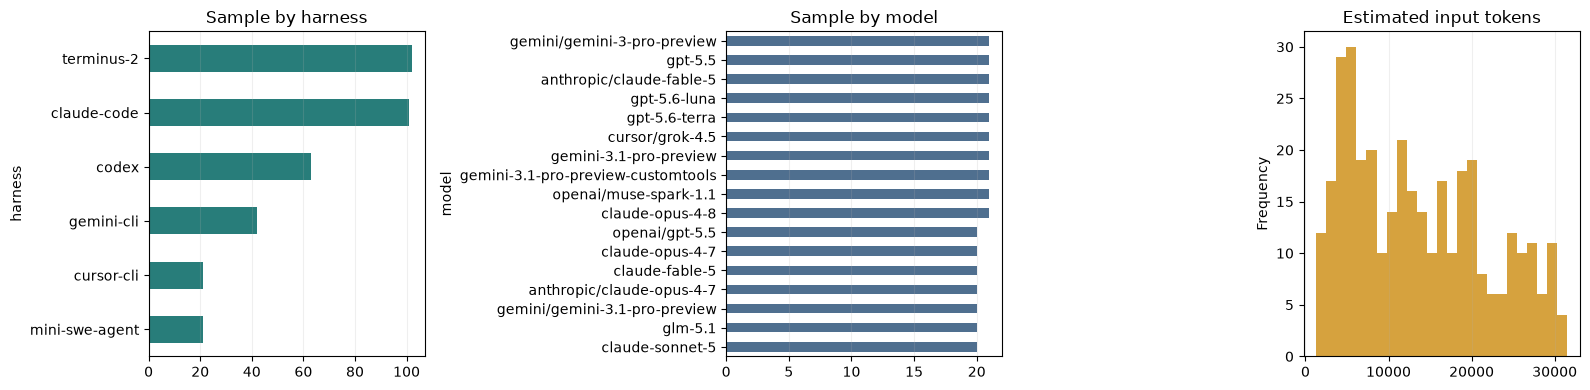

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sample_df['harness'].value_counts().sort_values().plot.barh(ax=axes[0], color='#287d7a', title='Sample by harness')
sample_df['model'].value_counts().sort_values().plot.barh(ax=axes[1], color='#4f6f8f', title='Sample by model')
sample_df['estimated_input_tokens'].plot.hist(ax=axes[2], bins=25, color='#d6a23e', title='Estimated input tokens')
for ax in axes:
    ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

## Ollama connection and resumable extraction

Every API request contains exactly one task and one trajectory. The function does not send earlier trajectories as chat history. Successful outputs and malformed responses are saved immediately. Completed IDs are never submitted again. Failed IDs are quarantined and skipped, so one malformed response cannot stop the run or consume another request. An empty `decisions` list is a valid completed extraction.

In [ ]:
def ollama_tags():
    response = requests.get(f'{OLLAMA_BASE_URL}/api/tags', timeout=10)
    response.raise_for_status()
    return response.json()

try:
    tags = ollama_tags()
    installed_models = sorted(model.get('name', '') for model in tags.get('models', []))
    OLLAMA_AVAILABLE = True
    print('The local Ollama service is available.')
    display(pd.DataFrame({'available_model': installed_models}))
except requests.RequestException as exc:
    tags = None
    installed_models = []
    OLLAMA_AVAILABLE = False
    print('The extraction stage is unavailable because the local Ollama service is not reachable.')
    print(type(exc).__name__, exc)

The local Ollama service is available.


,available_model
0,deepseek-v4-flash:cloud
1,gpt-oss:120b-cloud
2,qwen3-embedding:0.6b


In [ ]:
VISIBILITY = {'EXPLICIT', 'CONTEXTUAL', 'UNAVAILABLE'}

def validate_extraction(parsed, valid_steps):
    errors = []
    if not isinstance(parsed, dict):
        return ['Root output is not an object.']
    decisions = parsed.get('decisions')
    if not isinstance(decisions, list):
        return errors + ['decisions is not a list.']
    for index, event in enumerate(decisions):
        prefix = f'decisions[{index}]'
        if not isinstance(event, dict):
            errors.append(f'{prefix} is not an object.')
            continue
        source_steps = event.get('source_steps')
        if not isinstance(source_steps, list) or not source_steps:
            errors.append(f'{prefix}.source_steps is empty or invalid.')
        elif any(step not in valid_steps for step in source_steps):
            errors.append(f'{prefix}.source_steps contains an unknown step.')
        for field in ('decision_summary', 'decision_type_label'):
            if not isinstance(event.get(field), str) or not event[field].strip():
                errors.append(f'{prefix}.{field} is empty.')
        if event.get('visibility') not in VISIBILITY:
            errors.append(f'{prefix}.visibility is invalid.')
    return errors

def safe_filename(identifier):
    safe = re.sub(r'[^A-Za-z0-9._-]+', '_', str(identifier)).strip('._')
    digest = hashlib.sha1(str(identifier).encode('utf-8')).hexdigest()[:10]
    return f'{safe[:80]}__{digest}.json'

def atomic_write_json(path, value):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)

def parse_message_content(content):
    content = str(content or '').strip()
    if content.startswith('```'):
        content = re.sub(r'^```(?:json)?\s*|\s*```$', '', content, flags=re.IGNORECASE | re.DOTALL).strip()
    return json.loads(content)

def read_completed_output(path, expected_trajectory_id=None):
    if not path.exists():
        return None
    try:
        saved = json.loads(path.read_text(encoding='utf-8'))
        parsed = saved.get('parsed')
        trajectory_id = str(saved.get('trajectory_id') or '')
        valid = (
            trajectory_id
            and isinstance(parsed, dict)
            and isinstance(parsed.get('decisions'), list)
            and (expected_trajectory_id is None or trajectory_id == str(expected_trajectory_id))
        )
        return saved if valid else None
    except (OSError, json.JSONDecodeError):
        return None

def rebuild_completion_index():
    rows = []
    for path in sorted(RAW_RESPONSE_DIR.glob('*.json')):
        saved = read_completed_output(path)
        if saved is None:
            continue
        rows.append({
            'trajectory_id': str(saved['trajectory_id']),
            'task_id': saved.get('task_id'),
            'extractor_model': saved.get('extractor_model'),
            'n_decisions': len(saved['parsed']['decisions']),
            'output_path': str(path),
        })
    columns = ['trajectory_id', 'task_id', 'extractor_model', 'n_decisions', 'output_path']
    index_df = pd.DataFrame(rows, columns=columns)
    index_df.to_csv(OUTPUT_DIR / 'completed_trajectory_index.csv', index=False)
    return index_df

def read_failed_output(path):
    if not path.exists():
        return None
    try:
        saved = json.loads(path.read_text(encoding='utf-8'))
        return saved if saved.get('status') == 'failed' and saved.get('trajectory_id') else None
    except (OSError, json.JSONDecodeError):
        return None

def record_failed_attempt(record, raw_response, error_text, source='ollama'):
    trajectory_id = trial_id_of(record)
    path = FAILED_RESPONSE_DIR / safe_filename(trajectory_id)
    previous = read_failed_output(path) or {}
    attempts = list(previous.get('attempts') or [])
    attempts.append({
        'attempt': len(attempts) + 1,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'source': source,
        'error': str(error_text),
        'ollama_response': raw_response,
    })
    saved = {
        'status': 'failed',
        'trajectory_id': trajectory_id,
        'task_id': record.get('task_id'),
        'harness': record.get('harness') or record.get('agent'),
        'source_model': record.get('model'),
        'extractor_model': EXTRACTOR_MODEL,
        'extraction_signature': extraction_signature(),
        'attempts': attempts,
    }
    atomic_write_json(path, saved)
    return path

def rebuild_failure_index(completed_ids=None):
    completed_ids = set(map(str, completed_ids or []))
    rows = []
    for path in sorted(FAILED_RESPONSE_DIR.glob('*.json')):
        saved = read_failed_output(path)
        if saved is None or str(saved['trajectory_id']) in completed_ids:
            continue
        attempts = saved.get('attempts') or []
        rows.append({
            'trajectory_id': str(saved['trajectory_id']),
            'task_id': saved.get('task_id'),
            'harness': saved.get('harness'),
            'source_model': saved.get('source_model'),
            'attempt_count': len(attempts),
            'last_error': attempts[-1].get('error') if attempts else None,
            'output_path': str(path),
        })
    columns = ['trajectory_id', 'task_id', 'harness', 'source_model', 'attempt_count', 'last_error', 'output_path']
    index_df = pd.DataFrame(rows, columns=columns)
    index_df.to_csv(OUTPUT_DIR / 'failed_trajectory_index.csv', index=False)
    return index_df

def extraction_signature():
    value = json.dumps({
        'model': EXTRACTOR_MODEL,
        'system_prompt': SYSTEM_PROMPT,
        'schema': OUTPUT_SCHEMA,
    }, ensure_ascii=False, sort_keys=True)
    return hashlib.sha256(value.encode('utf-8')).hexdigest()

def call_ollama(record):
    payload = {
        'model': EXTRACTOR_MODEL,
        'messages': [
            {'role': 'system', 'content': SYSTEM_PROMPT},
            {'role': 'user', 'content': build_user_prompt(record)},
        ],
        'stream': False,
        'think': False,
        'format': OUTPUT_SCHEMA,
        'options': {
            'temperature': 0,
            'seed': SEED,
            'num_predict': MAX_OUTPUT_TOKENS,
        },
    }
    response = requests.post(
        f'{OLLAMA_BASE_URL}/api/chat',
        json=payload,
        timeout=REQUEST_TIMEOUT_SECONDS,
    )
    response.raise_for_status()
    return response.json()

def process_record(record):
    trajectory_id = trial_id_of(record)
    output_path = RAW_RESPONSE_DIR / safe_filename(trajectory_id)
    if read_completed_output(output_path, trajectory_id) is not None:
        return 'skipped', output_path
    last_error = None
    last_failure_path = None
    for _ in range(1):
        raw = None
        try:
            raw = call_ollama(record)
            parsed = parse_message_content((raw.get('message') or {}).get('content'))
            valid_steps = {row['step'] for row in compact_steps(record)}
            errors = validate_extraction(parsed, valid_steps)
            if errors:
                raise ValueError('; '.join(errors))
            saved = {
                'status': 'complete',
                'trajectory_id': trajectory_id,
                'task_id': record.get('task_id'),
                'harness': record.get('harness') or record.get('agent'),
                'source_model': record.get('model'),
                'extractor_model': EXTRACTOR_MODEL,
                'extractor_base_url': OLLAMA_BASE_URL,
                'extraction_signature': extraction_signature(),
                'created_at_utc': datetime.now(timezone.utc).isoformat(),
                'parsed': parsed,
                'ollama_response': raw,
            }
            atomic_write_json(output_path, saved)
            return 'written', output_path
        except Exception as exc:
            last_error = exc
            last_failure_path = record_failed_attempt(record, raw, f'{type(exc).__name__}: {exc}')
    return f'error: {type(last_error).__name__}: {last_error}', last_failure_path or output_path


In [ ]:
def iter_jsonl(path):
    with path.open('r', encoding='utf-8') as handle:
        for line in handle:
            if line.strip():
                yield json.loads(line)

sample_records = list(iter_jsonl(selected_path))
sample_by_id = {trial_id_of(record): record for record in sample_records}
sample_ids = set(sample_by_id)
completed_index_df = rebuild_completion_index()
all_completed_ids = set(completed_index_df.get('trajectory_id', pd.Series(dtype=str)).astype(str))
completed_ids = sample_ids & all_completed_ids

# Preserve errors from an older notebook run whose malformed raw responses were not saved.
legacy_log_path = OUTPUT_DIR / 'latest_run_log.csv'
if legacy_log_path.exists():
    legacy_log_df = pd.read_csv(legacy_log_path)
    for row in legacy_log_df.to_dict('records'):
        trajectory_id = str(row.get('trajectory_id') or '')
        status = str(row.get('status') or '')
        failed_path = FAILED_RESPONSE_DIR / safe_filename(trajectory_id)
        if status.startswith('error') and trajectory_id in sample_by_id and trajectory_id not in completed_ids and not failed_path.exists():
            record_failed_attempt(sample_by_id[trajectory_id], None, status, source='legacy_run_log')

failed_index_df = rebuild_failure_index(completed_ids)
quarantined_ids = sample_ids & set(failed_index_df['trajectory_id'].astype(str))
print({
    'already_completed': len(completed_ids),
    'quarantined_before_run': len(quarantined_ids),
    'not_yet_attempted': len(sample_ids - completed_ids - quarantined_ids),
})

run_log = []
if RUN_MODE == 'sample_only':
    print('Sampling is complete. Set RUN_MODE to test_one or full before LLM calls.')
else:
    if not OLLAMA_AVAILABLE:
        raise RuntimeError('Start the signed-in Ollama application before extraction.')

    main_records = [
        record for record in sample_records
        if trial_id_of(record) not in completed_ids and trial_id_of(record) not in quarantined_ids
    ]
    if RUN_MODE == 'test_one':
        main_records = main_records[:1]
    elif MAX_NEW_RECORDS is not None:
        main_records = main_records[:MAX_NEW_RECORDS]

    for record in tqdm(main_records, desc=f'Ollama extraction: {RUN_MODE}'):
        status, path = process_record(record)
        run_log.append({'phase': 'main', 'trajectory_id': trial_id_of(record), 'status': status, 'path': str(path)})
        if status.startswith('error'):
            print(run_log[-1])
        if len(run_log) % 10 == 0:
            pd.DataFrame(run_log).to_csv(OUTPUT_DIR / 'latest_run_log.csv', index=False)

    if run_log:
        pd.DataFrame(run_log).to_csv(OUTPUT_DIR / 'latest_run_log.csv', index=False)
        display(pd.DataFrame(run_log).groupby(['phase', 'status']).size().rename('n').to_frame())

completed_index_df = rebuild_completion_index()
completed_ids = sample_ids & set(completed_index_df['trajectory_id'].astype(str))
failed_index_df = rebuild_failure_index(completed_ids)
quarantined_ids = sample_ids & set(failed_index_df['trajectory_id'].astype(str))
status_summary = pd.Series({
    'sample_size': len(sample_ids),
    'completed': len(completed_ids),
    'failed_and_skipped': len(quarantined_ids),
    'not_attempted': len(sample_ids - completed_ids - quarantined_ids),
}, name='n')
display(status_summary.to_frame())

{'already_completed': 350, 'quarantined_before_run': 0, 'not_yet_attempted': 0}


Ollama extraction: full: 0it [00:00, ?it/s]


,n
sample_size,350
completed,350
failed_and_skipped,0
not_attempted,0


## Consolidate saved decision events

The consolidation stage reconstructs the analysis table from the saved per-trajectory files. It is independent of the LLM extraction calls and can be repeated without resubmitting trajectories.

In [ ]:
decision_rows = []
trajectory_rows = []
for output_path in sorted(RAW_RESPONSE_DIR.glob('*.json')):
    saved = read_completed_output(output_path)
    if saved is None:
        continue
    parsed = saved.get('parsed') or {}
    decisions = parsed.get('decisions') or []
    raw = saved.get('ollama_response') or {}
    trajectory_rows.append({
        'trajectory_id': saved.get('trajectory_id'),
        'task_id': saved.get('task_id'),
        'harness': saved.get('harness'),
        'source_model': saved.get('source_model'),
        'n_decisions': len(decisions),
        'prompt_tokens': raw.get('prompt_eval_count'),
        'completion_tokens': raw.get('eval_count'),
        'total_tokens': (raw.get('prompt_eval_count') or 0) + (raw.get('eval_count') or 0),
        'total_duration_seconds': (raw.get('total_duration') or 0) / 1e9,
    })
    for event in decisions:
        decision_rows.append({
            'trajectory_id': saved.get('trajectory_id'),
            'task_id': saved.get('task_id'),
            'harness': saved.get('harness'),
            'source_model': saved.get('source_model'),
            'source_steps': ','.join(map(str, event.get('source_steps') or [])),
            'decision_summary': event.get('decision_summary'),
            'decision_type_label': event.get('decision_type_label'),
            'visibility': event.get('visibility'),
        })

trajectory_results_df = pd.DataFrame(trajectory_rows)
decisions_df = pd.DataFrame(decision_rows)
if not trajectory_results_df.empty:
    trajectory_results_df.to_csv(OUTPUT_DIR / 'trajectory_extraction_summary.csv', index=False)
if not decisions_df.empty:
    decisions_df.to_csv(OUTPUT_DIR / 'decision_events.csv', index=False)

print({'completed_trajectories': len(trajectory_results_df), 'decision_events': len(decisions_df)})
if not decisions_df.empty:
    display(decisions_df['visibility'].value_counts(dropna=False).rename('n').to_frame())
    display(decisions_df.head(10))

{'completed_trajectories': 350, 'decision_events': 2194}


,n
visibility,
EXPLICIT,2026
CONTEXTUAL,168


,trajectory_id,task_id,harness,source_model,source_steps,decision_summary,decision_type_label,visibility
0,002b8f8f-b83e-5f90-8294-1754c64c424c,terminal-bench/financial-document-processor,terminus-2,openai/gpt-5.5,2,"The agent ran commands to check for the presence of pdftotext, tesseract, and python3, confirming which processing tools are available.",Tool availability check,EXPLICIT
1,002b8f8f-b83e-5f90-8294-1754c64c424c,terminal-bench/financial-document-processor,terminus-2,openai/gpt-5.5,7,"The agent executed apt-get update and installed the packages file, binutils, poppler-utils, tesseract-ocr, and imagemagick to provide ne...",Package installation via apt-get,EXPLICIT
2,002b8f8f-b83e-5f90-8294-1754c64c424c,terminal-bench/financial-document-processor,terminus-2,openai/gpt-5.5,9,"The agent created working directories and extracted text from PDFs using pdftotext -layout and from JPGs using tesseract with --psm 6, p...",Text extraction method selection,EXPLICIT
3,002b8f8f-b83e-5f90-8294-1754c64c424c,terminal-bench/financial-document-processor,terminus-2,openai/gpt-5.5,12,"The agent searched the extracted text files for keywords like invoice, total, amount, vat, etc., to decide which documents are invoices.",Keyword-based document classification,EXPLICIT
4,002b8f8f-b83e-5f90-8294-1754c64c424c,terminal-bench/financial-document-processor,terminus-2,openai/gpt-5.5,14,"The agent chose to mark the overall task as complete, finalizing the solution.",Task completion confirmation,EXPLICIT
5,00a246aa-c6e1-56ba-ac69-766d0f5ed7dc,terminal-bench/dna-assembly,gemini-cli,gemini-3.1-pro-preview,7,Installed the primer3 package using apt-get to enable melting temperature calculations.,Install primer3 package,EXPLICIT
6,00a246aa-c6e1-56ba-ac69-766d0f5ed7dc,terminal-bench/dna-assembly,gemini-cli,gemini-3.1-pro-preview,11,Created a Node script (parse.js) to read the FASTA file and store each sequence in a JSON object.,Parse FASTA sequences via Node,CONTEXTUAL
7,00a246aa-c6e1-56ba-ac69-766d0f5ed7dc,terminal-bench/dna-assembly,gemini-cli,gemini-3.1-pro-preview,13,"Wrote an alignment script (align.js) to locate each fragment within the output plasmid, handling exact and partial matches.",Align fragments to output,CONTEXTUAL
8,00a246aa-c6e1-56ba-ac69-766d0f5ed7dc,terminal-bench/dna-assembly,gemini-cli,gemini-3.1-pro-preview,15,Implemented a mapping script (map.js) to determine approximate start/end positions of each fragment in the output sequence.,Map fragment boundaries,CONTEXTUAL
9,00a246aa-c6e1-56ba-ac69-766d0f5ed7dc,terminal-bench/dna-assembly,gemini-cli,gemini-3.1-pro-preview,17,Added a verification script (verify.js) that checks presence and orientation of each fragment in the assembled output.,Verify fragment inclusion,CONTEXTUAL


## Baseline embedding of labels and summaries

Each clustering string combines the free-text type label with the decision summary. The same fixed local Qwen embedding model is used for every event. This stage does not consume Ollama Cloud credits. The embedding cache is invalidated when the model or event text changes.

In [ ]:
def normalize_free_label(value):
    value = re.sub(r'[^a-z0-9]+', ' ', str(value or '').lower())
    return re.sub(r'\s+', ' ', value).strip()

def call_ollama_embed(texts):
    response = requests.post(
        f'{OLLAMA_BASE_URL}/api/embed',
        json={'model': EMBEDDING_MODEL, 'input': texts, 'truncate': False},
        timeout=REQUEST_TIMEOUT_SECONDS,
    )
    response.raise_for_status()
    return np.asarray(response.json()['embeddings'], dtype=np.float32)

embeddings = None
if decisions_df.empty:
    print('Embedding is unavailable because no consolidated decision events are present.')
else:
    decisions_df = decisions_df.copy()
    decisions_df['normalized_free_label'] = decisions_df['decision_type_label'].map(normalize_free_label)
    decisions_df['embedding_text'] = (
        'Design decision type: ' + decisions_df['normalized_free_label']
        + '. Decision: ' + decisions_df['decision_summary'].fillna('').str.strip()
    )
    fingerprint_input = EMBEDDING_MODEL + '\n' + '\n'.join(
        decisions_df['trajectory_id'].astype(str) + '::' + decisions_df['source_steps'].astype(str) + '::' + decisions_df['embedding_text']
    )
    fingerprint = hashlib.sha256(fingerprint_input.encode('utf-8')).hexdigest()
    embedding_path = OUTPUT_DIR / 'decision_embeddings.npy'
    embedding_manifest_path = OUTPUT_DIR / 'decision_embeddings_manifest.json'
    cached = None
    if embedding_path.exists() and embedding_manifest_path.exists():
        cached = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
    if cached and cached.get('fingerprint') == fingerprint:
        embeddings = np.load(embedding_path)
        print('Loaded cached embeddings:', embeddings.shape)
    else:
        if not OLLAMA_AVAILABLE:
            raise RuntimeError('The local Ollama service and configured embedding model are required for this stage.')
        batches = []
        texts = decisions_df['embedding_text'].tolist()
        for start in tqdm(range(0, len(texts), 64), desc='Embedding decisions'):
            batches.append(call_ollama_embed(texts[start:start + 64]))
        embeddings = np.vstack(batches)
        np.save(embedding_path, embeddings)
        atomic_write_json(embedding_manifest_path, {
            'fingerprint': fingerprint,
            'embedding_model': EMBEDDING_MODEL,
            'embedding_base_url': OLLAMA_BASE_URL,
            'n_events': len(decisions_df),
            'dimensions': int(embeddings.shape[1]),
        })
        print('Saved embeddings:', embeddings.shape)

Loaded cached embeddings: (2194, 1024)


## Baseline clustering of emergent groups

A candidate number of clusters is selected using the cosine silhouette score. The resulting structure is exploratory rather than a final taxonomy. Cluster interpretation is based on representative events, outliers, coherence, and possible task-specific vocabulary.

Selecting cluster count: 100%|██████████| 19/19 [01:04<00:00,  3.42s/it]


,k,silhouette_score
18,20,0.091269
16,18,0.083868
17,19,0.082345
15,17,0.079539
14,16,0.078548
0,2,0.078500
13,15,0.073462
12,14,0.072993
11,13,0.068782
10,12,0.061065


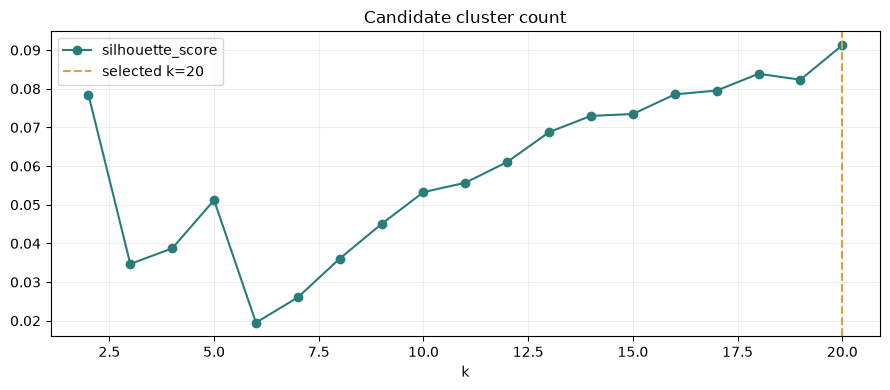

Selected cluster count: 20


In [ ]:
cluster_model = None
if embeddings is None or len(embeddings) < 6:
    print('At least six embedded decision events are required for this clustering cell.')
else:
    X = normalize(embeddings)
    maximum_k = min(20, max(2, int(np.sqrt(len(X)))), len(X) - 1)
    candidate_k = list(range(2, maximum_k + 1))
    scores = []
    models = {}
    for k in tqdm(candidate_k, desc='Selecting cluster count'):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
        labels = model.fit_predict(X)
        score = silhouette_score(X, labels, metric='cosine', sample_size=min(2_000, len(X)), random_state=SEED)
        scores.append(score)
        models[k] = model
    best_k = candidate_k[int(np.argmax(scores))]
    cluster_model = models[best_k]
    decisions_df['cluster'] = cluster_model.labels_
    decisions_df.to_csv(OUTPUT_DIR / 'cluster_assignments.csv', index=False)

    score_df = pd.DataFrame({'k': candidate_k, 'silhouette_score': scores})
    display(score_df.sort_values('silhouette_score', ascending=False).head(10))
    ax = score_df.plot(x='k', y='silhouette_score', marker='o', figsize=(9, 4), color='#287d7a', legend=False)
    ax.axvline(best_k, color='#d6a23e', linestyle='--', label=f'selected k={best_k}')
    ax.set_title('Candidate cluster count')
    ax.legend()
    ax.grid(alpha=.2)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'cluster_count_selection.png', dpi=180, bbox_inches='tight')
    plt.show()
    print('Selected cluster count:', best_k)

In [ ]:
if cluster_model is None:
    print('Cluster interpretation is unavailable because no fitted clustering model is present.')
else:
    X = normalize(embeddings)
    distances = np.linalg.norm(X - cluster_model.cluster_centers_[decisions_df['cluster']], axis=1)
    decisions_df['distance_to_centroid'] = distances

    summary_rows = []
    representative_rows = []
    for cluster_id, group in decisions_df.groupby('cluster'):
        top_labels = group['normalized_free_label'].value_counts().head(6)
        summary_rows.append({
            'cluster': cluster_id,
            'n_events': len(group),
            'unique_tasks': group['task_id'].nunique(),
            'unique_harnesses': group['harness'].nunique(),
            'unique_models': group['source_model'].nunique(),
            'top_free_labels': '; '.join(f'{label} ({count})' for label, count in top_labels.items()),
        })
        representative_rows.extend(
            group.nsmallest(5, 'distance_to_centroid').assign(representative_rank=range(1, min(5, len(group)) + 1)).to_dict('records')
        )

    cluster_summary_df = pd.DataFrame(summary_rows).sort_values('n_events', ascending=False)
    representatives_df = pd.DataFrame(representative_rows).sort_values(['cluster', 'representative_rank'])
    cluster_summary_df.to_csv(OUTPUT_DIR / 'cluster_summary.csv', index=False)
    representatives_df.to_csv(OUTPUT_DIR / 'cluster_representatives.csv', index=False)
    display(cluster_summary_df)
    display(representatives_df[['cluster', 'representative_rank', 'decision_type_label', 'decision_summary', 'task_id', 'harness', 'source_model']].head(30))

,cluster,n_events,unique_tasks,unique_harnesses,unique_models,top_free_labels
5,5,239,43,6,17,set source priority order (3); generate conflict report json (3); write extracted flag to results file (2); select meeting time slot (2)...
6,6,196,42,6,17,defer tail integrability check (1); introduce batch optimizer implementation (1); revise sqlite cell parsing implementation (1); rename ...
1,1,168,48,6,17,execute comprehensive test suite (2); verify fragment inclusion (1); reuse uniform variate for acceptance (1); add tail quantile and med...
9,9,168,26,6,17,install required build tools (4); install rcppeigen dependency (3); install binary to usr local bin (2); install build dependencies (2);...
0,0,158,39,6,17,install required python packages (7); install python3 interpreter (3); install remotes r package (2); select specific grpcio package ver...
12,12,151,18,6,17,define recovered model architecture (2); p2pop batch isend irecv for pipeline communication (1); recreate causal mask and position ids (...
8,8,137,29,5,15,pre screen log concavity of candidates (1); run additional distribution verification (1); large sample performance validation (1); choos...
14,14,123,17,5,14,adopt mog2 background subtraction (2); map fragment boundaries (1); filter low density initial points (1); verify non log concave detect...
19,19,104,11,6,15,merge branch2 into branch1 (4); create post receive deployment hook (2); initialize bare repository (2); create dedicated git user (2); ...
16,16,103,14,6,17,hash and entropy analysis of files (1); entropy calculation of disk image (1); node xor entropy comparison (1); bit level password patte...


,cluster,representative_rank,decision_type_label,decision_summary,task_id,harness,source_model
0,0,1,Install required Python packages,"Installed required Python packages (torch, torchvision, pandas, opencv, etc.)",terminal-bench/sam-cell-seg,terminus-2,gemini/gemini-3.1-pro-preview
1,0,2,Install Python interpreter,Installed Python3 so that subsequent analysis scripts could be executed.,terminal-bench/dna-insert,cursor-cli,cursor/grok-4.5
2,0,3,Install runtime package dependencies,"Installed runtime libraries networkx, planarity, peewee, vispy, sympy, appdirs, requests, tqdm, and pytest.",terminal-bench/build-cython-ext,gemini-cli,gemini-3.1-pro-preview
3,0,4,Install Python and development tools,"Agent installed python3, pip, and related packages to enable script execution.",terminal-bench/dna-assembly,gemini-cli,gemini-3.1-pro-preview
4,0,5,Install missing Python interpreter,Installed python3 after failing to locate an interpreter.,terminal-bench/polyglot-c-py,claude-code,glm-5.1
5,1,1,Execute comprehensive validation suite,Ran a Python validation script with many test cases to confirm correctness,terminal-bench/circuit-fibsqrt,terminus-2,anthropic/claude-fable-5
6,1,2,Run solution and tests,Executed solve.py and ran check.py to verify correctness of the solution.,terminal-bench/regex-chess,terminus-2,gemini/gemini-3-pro-preview
7,1,3,Select numeric pattern test,Ran inference on a numeric sequence prompt to check continuation behavior,terminal-bench/gpt2-codegolf,claude-code,claude-fable-5
8,1,4,Validate plans against constraints,"The agent runs a verification script that checks coverage, shape validity, batch consistency, and all metric thresholds.",terminal-bench/llm-inference-batching-scheduler,claude-code,claude-fable-5
9,1,5,Attempt complex command substitution,The agent attempted to compute the total number of [ERROR] entries across a large set of log files using a single command with command s...,terminal-bench/log-summary-date-ranges,gemini-cli,gemini-3.1-pro-preview


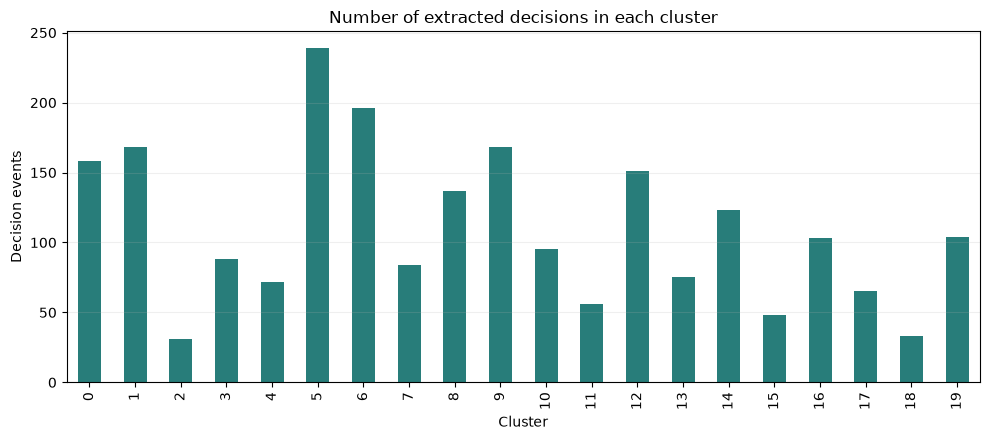

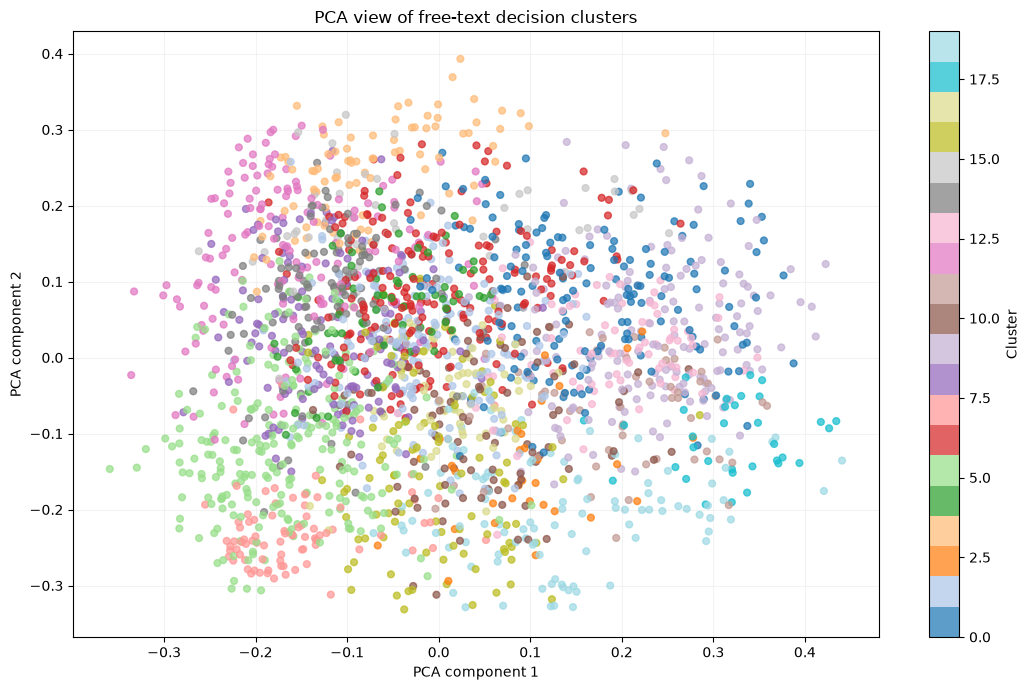

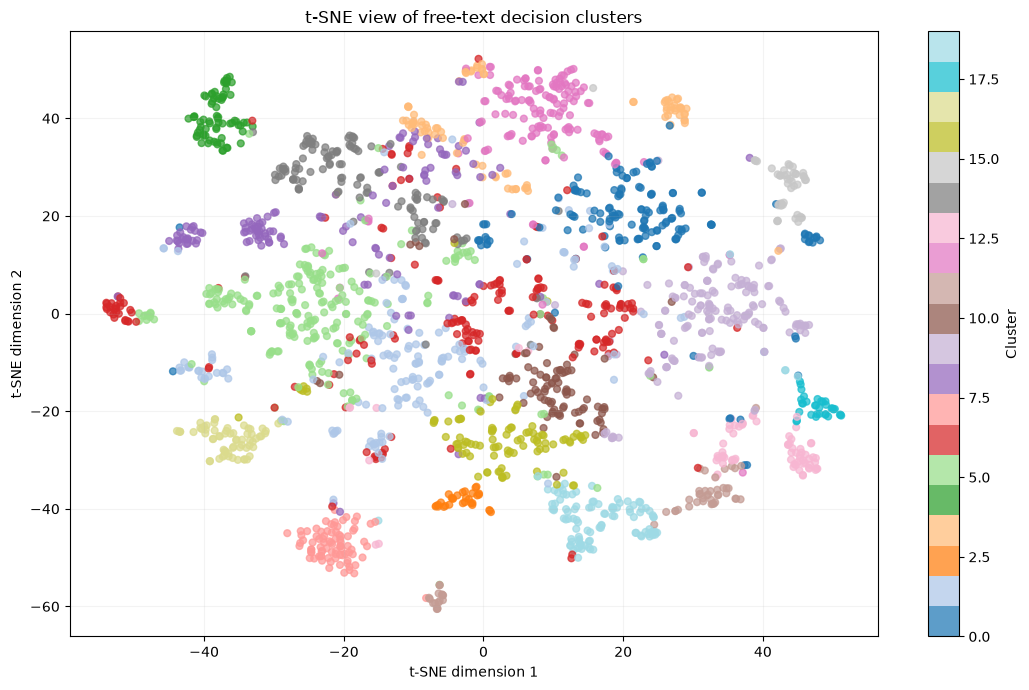

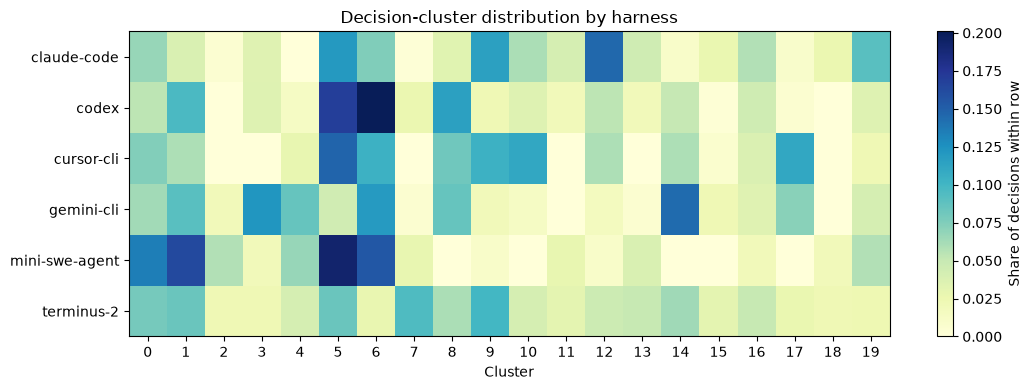

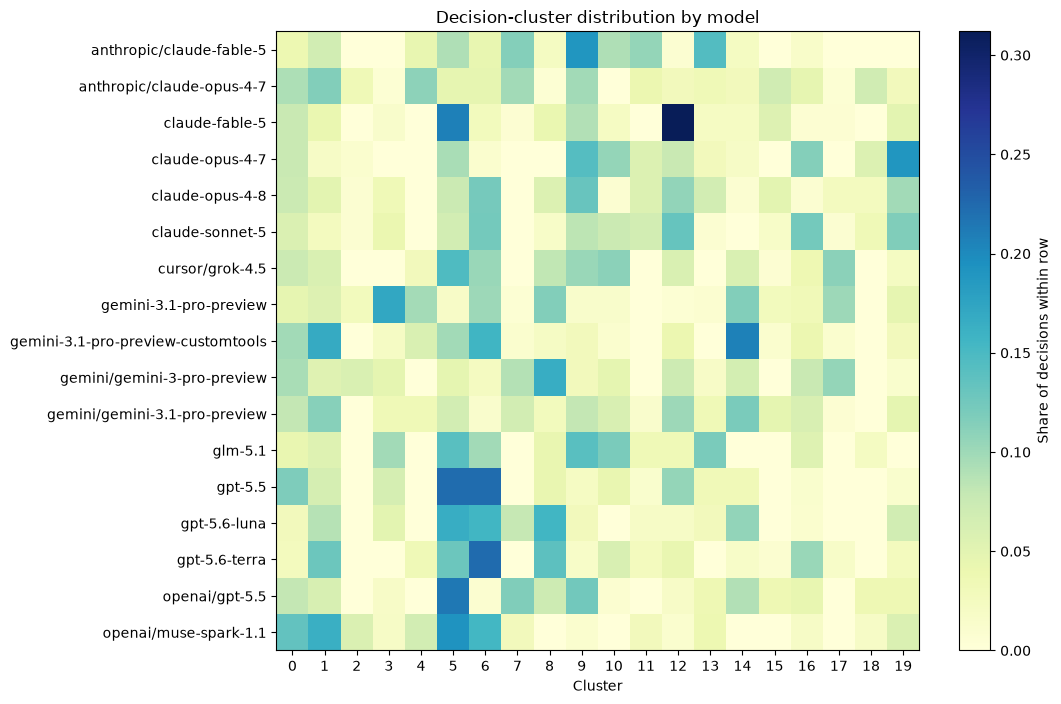

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
harness,,,,,,,,,,,,,,,,,,,,
claude-code,0.067,0.038,0.005,0.034,0.000,0.120,0.075,0.002,0.033,0.115,0.060,0.041,0.146,0.045,0.010,0.027,0.058,0.009,0.026,0.091
codex,0.054,0.096,0.000,0.035,0.013,0.169,0.201,0.026,0.115,0.022,0.035,0.019,0.054,0.019,0.051,0.003,0.045,0.006,0.000,0.035
cursor-cli,0.074,0.059,0.000,0.000,0.029,0.147,0.103,0.000,0.081,0.103,0.110,0.000,0.059,0.000,0.059,0.007,0.037,0.110,0.000,0.022
gemini-cli,0.063,0.091,0.019,0.122,0.085,0.044,0.119,0.006,0.085,0.019,0.013,0.000,0.016,0.006,0.144,0.022,0.034,0.072,0.000,0.041
mini-swe-agent,0.135,0.163,0.058,0.019,0.067,0.192,0.154,0.029,0.000,0.010,0.000,0.029,0.010,0.038,0.000,0.000,0.019,0.000,0.019,0.058
terminus-2,0.079,0.084,0.022,0.022,0.041,0.084,0.028,0.095,0.060,0.099,0.041,0.031,0.047,0.050,0.064,0.031,0.050,0.027,0.022,0.024


cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
source_model,,,,,,,,,,,,,,,,,,,,
anthropic/claude-fable-5,0.038,0.068,0.000,0.000,0.045,0.091,0.045,0.114,0.023,0.189,0.091,0.106,0.008,0.144,0.023,0.000,0.015,0.000,0.000,0.000
anthropic/claude-opus-4-7,0.092,0.115,0.034,0.006,0.109,0.046,0.046,0.098,0.006,0.098,0.000,0.040,0.029,0.034,0.029,0.069,0.046,0.006,0.069,0.029
claude-fable-5,0.076,0.042,0.000,0.014,0.000,0.208,0.028,0.007,0.042,0.090,0.021,0.000,0.312,0.021,0.021,0.056,0.007,0.007,0.000,0.049
claude-opus-4-7,0.076,0.019,0.010,0.000,0.000,0.095,0.010,0.000,0.000,0.143,0.105,0.057,0.076,0.029,0.019,0.000,0.114,0.000,0.057,0.190
claude-opus-4-8,0.074,0.049,0.008,0.033,0.000,0.074,0.123,0.000,0.057,0.131,0.008,0.057,0.107,0.066,0.008,0.049,0.008,0.025,0.025,0.098
claude-sonnet-5,0.058,0.025,0.008,0.041,0.000,0.066,0.124,0.000,0.017,0.083,0.074,0.066,0.132,0.008,0.000,0.017,0.124,0.008,0.033,0.116
cursor/grok-4.5,0.074,0.059,0.000,0.000,0.029,0.147,0.103,0.000,0.081,0.103,0.110,0.000,0.059,0.000,0.059,0.007,0.037,0.110,0.000,0.022
gemini-3.1-pro-preview,0.046,0.055,0.028,0.171,0.097,0.018,0.101,0.005,0.115,0.014,0.014,0.000,0.005,0.009,0.115,0.028,0.032,0.101,0.000,0.046
gemini-3.1-pro-preview-customtools,0.098,0.167,0.000,0.020,0.059,0.098,0.157,0.010,0.020,0.029,0.010,0.000,0.039,0.000,0.206,0.010,0.039,0.010,0.000,0.029


In [ ]:
if cluster_model is not None:
    X = normalize(embeddings)

    cluster_sizes = decisions_df['cluster'].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    cluster_sizes.plot.bar(ax=ax, color='#287d7a')
    ax.set_title('Number of extracted decisions in each cluster')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Decision events')
    ax.grid(axis='y', alpha=.2)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'cluster_sizes.png', dpi=180, bbox_inches='tight')
    plt.show()

    X_pca = PCA(n_components=2, random_state=SEED).fit_transform(X)
    fig, ax = plt.subplots(figsize=(11, 7))
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=decisions_df['cluster'], cmap='tab20', s=24, alpha=.72)
    ax.set_title('PCA view of free-text decision clusters')
    ax.set_xlabel('PCA component 1')
    ax.set_ylabel('PCA component 2')
    ax.grid(alpha=.15)
    plt.colorbar(scatter, ax=ax, label='Cluster')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'cluster_map_pca.png', dpi=180, bbox_inches='tight')
    plt.show()

    # t-SNE is only a visual aid; cluster assignment still comes from the full embeddings.
    reduced_dimensions = min(50, X.shape[1], len(X) - 1)
    X_for_tsne = PCA(n_components=reduced_dimensions, random_state=SEED).fit_transform(X)
    perplexity = min(30, max(5, (len(X) - 1) // 3))
    X_tsne = TSNE(
        n_components=2, perplexity=perplexity, init='pca', learning_rate='auto',
        random_state=SEED, max_iter=1_000,
    ).fit_transform(X_for_tsne)
    fig, ax = plt.subplots(figsize=(11, 7))
    scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=decisions_df['cluster'], cmap='tab20', s=24, alpha=.72)
    ax.set_title('t-SNE view of free-text decision clusters')
    ax.set_xlabel('t-SNE dimension 1')
    ax.set_ylabel('t-SNE dimension 2')
    ax.grid(alpha=.15)
    plt.colorbar(scatter, ax=ax, label='Cluster')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'cluster_map_tsne.png', dpi=180, bbox_inches='tight')
    plt.show()

    harness_distribution = pd.crosstab(decisions_df['harness'], decisions_df['cluster'], normalize='index').round(3)
    model_distribution = pd.crosstab(decisions_df['source_model'], decisions_df['cluster'], normalize='index').round(3)
    harness_distribution.to_csv(OUTPUT_DIR / 'cluster_distribution_by_harness.csv')
    model_distribution.to_csv(OUTPUT_DIR / 'cluster_distribution_by_model.csv')

    def plot_distribution_heatmap(table, title, filename):
        fig, ax = plt.subplots(figsize=(max(10, .55 * len(table.columns)), max(4, .42 * len(table.index))))
        image = ax.imshow(table.values, aspect='auto', cmap='YlGnBu', vmin=0, vmax=max(.01, table.values.max()))
        ax.set_xticks(range(len(table.columns)), table.columns)
        ax.set_yticks(range(len(table.index)), table.index)
        ax.set_xlabel('Cluster')
        ax.set_title(title)
        plt.colorbar(image, ax=ax, label='Share of decisions within row')
        plt.tight_layout()
        plt.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
        plt.show()

    plot_distribution_heatmap(harness_distribution, 'Decision-cluster distribution by harness', 'cluster_by_harness_heatmap.png')
    plot_distribution_heatmap(model_distribution, 'Decision-cluster distribution by model', 'cluster_by_model_heatmap.png')
    display(harness_distribution)
    display(model_distribution)

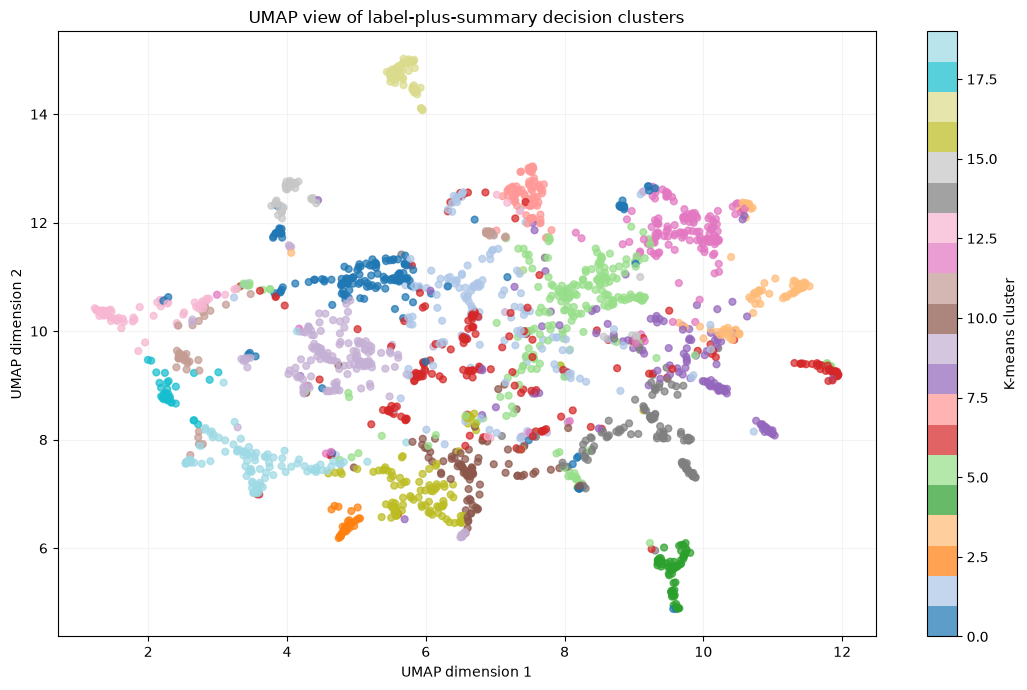

In [ ]:
# UMAP is an additional visual diagnostic; K-means cluster assignments are unchanged.
if cluster_model is None:
    print('No baseline clustering result is available for UMAP visualization.')
else:
    try:
        import umap.umap_ as umap
    except ImportError as exc:
        raise ImportError('Install umap-learn to generate the UMAP visualization.') from exc

    X = normalize(embeddings)
    baseline_umap = umap.UMAP(
        n_components=2,
        n_neighbors=min(30, len(X) - 1),
        min_dist=0.10,
        metric='cosine',
        random_state=SEED,
        n_jobs=1,
    )
    X_umap = baseline_umap.fit_transform(X)

    fig, ax = plt.subplots(figsize=(11, 7))
    scatter = ax.scatter(
        X_umap[:, 0], X_umap[:, 1],
        c=decisions_df['cluster'], cmap='tab20', s=24, alpha=.72,
    )
    ax.set_title('UMAP view of label-plus-summary decision clusters')
    ax.set_xlabel('UMAP dimension 1')
    ax.set_ylabel('UMAP dimension 2')
    ax.grid(alpha=.15)
    plt.colorbar(scatter, ax=ax, label='K-means cluster')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'cluster_map_umap.png', dpi=180, bbox_inches='tight')
    plt.show()

In [ ]:
if cluster_model is not None:
    review_parts = []
    for cluster_id, group in decisions_df.groupby('cluster'):
        central = group.nsmallest(3, 'distance_to_centroid')
        outliers = group.nlargest(2, 'distance_to_centroid')
        review_parts.append(central.assign(review_role='central example'))
        review_parts.append(outliers.assign(review_role='cluster outlier'))
    review_df = pd.concat(review_parts, ignore_index=True).sort_values(['cluster', 'review_role', 'distance_to_centroid'])
    review_columns = [
        'cluster', 'review_role', 'trajectory_id', 'task_id', 'harness', 'source_model',
        'source_steps', 'decision_type_label', 'decision_summary', 'visibility',
        'distance_to_centroid',
    ]
    review_df[review_columns].to_csv(OUTPUT_DIR / 'cluster_review_sample.csv', index=False)
    print('Saved cluster_review_sample.csv with central examples and outliers from every cluster.')

Saved cluster_review_sample.csv with central examples and outliers from every cluster.


## Label-only clustering experiment

The baseline above embeds the generated label together with the detailed decision summary. This comparison embeds **only `decision_type_label`**. It tests whether the freely generated labels contain enough recurring semantic structure without being dominated by task names, tools, files, or implementation details from the summaries.

K-means still operates on the complete normalized embedding vectors. PCA, UMAP, and t-SNE are used only to produce two-dimensional visual diagnostics; they do not determine the cluster assignments. The label-only files use a separate prefix, so the earlier baseline outputs are preserved.

In [ ]:
try:
    import umap.umap_ as umap
except ImportError as exc:
    raise ImportError('UMAP requires the umap-learn package. Run `uv sync` in the project root, restart the kernel, and rerun this cell.') from exc

label_only_embeddings = None
label_decisions_df = pd.DataFrame()
if decisions_df.empty:
    print('Label-only embedding is unavailable because no consolidated decision events are present.')
else:
    label_decisions_df = decisions_df.drop(columns=['cluster', 'distance_to_centroid'], errors='ignore').copy()
    label_decisions_df['normalized_free_label'] = label_decisions_df['decision_type_label'].map(normalize_free_label)
    label_decisions_df['label_embedding_text'] = label_decisions_df['normalized_free_label']

    fingerprint_input = EMBEDDING_MODEL + '\nlabel-only\n' + '\n'.join(
        label_decisions_df['trajectory_id'].astype(str)
        + '::' + label_decisions_df['source_steps'].astype(str)
        + '::' + label_decisions_df['label_embedding_text']
    )
    label_fingerprint = hashlib.sha256(fingerprint_input.encode('utf-8')).hexdigest()
    label_embedding_path = OUTPUT_DIR / 'label_only_decision_embeddings.npy'
    label_manifest_path = OUTPUT_DIR / 'label_only_decision_embeddings_manifest.json'

    cached = None
    if label_embedding_path.exists() and label_manifest_path.exists():
        cached = json.loads(label_manifest_path.read_text(encoding='utf-8'))
    if cached and cached.get('fingerprint') == label_fingerprint:
        label_only_embeddings = np.load(label_embedding_path)
        print('Loaded cached label-only embeddings:', label_only_embeddings.shape)
    else:
        if not OLLAMA_AVAILABLE:
            raise RuntimeError('The local Ollama service and configured embedding model are required for this stage.')
        batches = []
        label_texts = label_decisions_df['label_embedding_text'].tolist()
        for start in tqdm(range(0, len(label_texts), 64), desc='Embedding decision labels only'):
            batches.append(call_ollama_embed(label_texts[start:start + 64]))
        label_only_embeddings = np.vstack(batches)
        np.save(label_embedding_path, label_only_embeddings)
        atomic_write_json(label_manifest_path, {
            'fingerprint': label_fingerprint,
            'embedding_model': EMBEDDING_MODEL,
            'embedding_base_url': OLLAMA_BASE_URL,
            'embedding_input': 'decision_type_label only',
            'n_events': len(label_decisions_df),
            'dimensions': int(label_only_embeddings.shape[1]),
        })
        print('Saved label-only embeddings:', label_only_embeddings.shape)

Loaded cached label-only embeddings: (2194, 1024)


Selecting label-only cluster count: 100%|██████████| 19/19 [01:12<00:00,  3.82s/it]


,k,silhouette_score
17,19,0.077718
0,2,0.074218
1,3,0.073657
10,12,0.072302
3,5,0.071652
9,11,0.071069
8,10,0.071012
4,6,0.070802
11,13,0.070789
15,17,0.070512


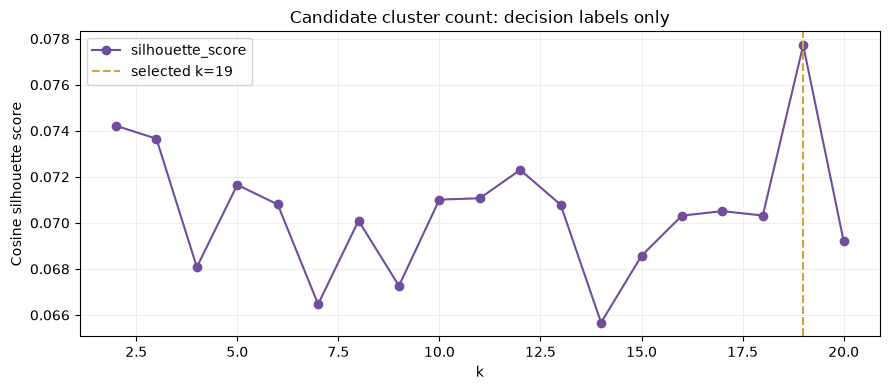

Selected label-only cluster count: 19


In [ ]:
label_cluster_model = None
label_score_df = pd.DataFrame()
if label_only_embeddings is None or len(label_only_embeddings) < 6:
    print('At least six label embeddings are required for clustering.')
else:
    X_label = normalize(label_only_embeddings)
    maximum_k = min(20, max(2, int(np.sqrt(len(X_label)))), len(X_label) - 1)
    candidate_k = list(range(2, maximum_k + 1))
    label_scores = []
    label_models = {}
    for k in tqdm(candidate_k, desc='Selecting label-only cluster count'):
        model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
        labels = model.fit_predict(X_label)
        score = silhouette_score(
            X_label, labels, metric='cosine',
            sample_size=min(2_000, len(X_label)), random_state=SEED,
        )
        label_scores.append(score)
        label_models[k] = model

    label_best_k = candidate_k[int(np.argmax(label_scores))]
    label_cluster_model = label_models[label_best_k]
    label_decisions_df['label_only_cluster'] = label_cluster_model.labels_
    label_decisions_df.to_csv(OUTPUT_DIR / 'label_only_cluster_assignments.csv', index=False)

    label_score_df = pd.DataFrame({'k': candidate_k, 'silhouette_score': label_scores})
    label_score_df.to_csv(OUTPUT_DIR / 'label_only_cluster_count_scores.csv', index=False)
    display(label_score_df.sort_values('silhouette_score', ascending=False).head(10))
    ax = label_score_df.plot(
        x='k', y='silhouette_score', marker='o', figsize=(9, 4),
        color='#6f4e9c', legend=False,
    )
    ax.axvline(label_best_k, color='#d6a23e', linestyle='--', label=f'selected k={label_best_k}')
    ax.set_title('Candidate cluster count: decision labels only')
    ax.set_ylabel('Cosine silhouette score')
    ax.legend()
    ax.grid(alpha=.2)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'label_only_cluster_count_selection.png', dpi=180, bbox_inches='tight')
    plt.show()
    print('Selected label-only cluster count:', label_best_k)

In [ ]:
if label_cluster_model is None:
    print('Label-only cluster interpretation is unavailable because no fitted clustering model is present.')
else:
    X_label = normalize(label_only_embeddings)
    label_centers = normalize(label_cluster_model.cluster_centers_)
    label_distances = np.linalg.norm(
        X_label - label_centers[label_decisions_df['label_only_cluster']], axis=1,
    )
    label_decisions_df['distance_to_label_centroid'] = label_distances

    label_summary_rows = []
    label_representative_rows = []
    for cluster_id, group in label_decisions_df.groupby('label_only_cluster'):
        top_labels = group['normalized_free_label'].value_counts().head(10)
        label_summary_rows.append({
            'cluster': cluster_id,
            'n_events': len(group),
            'unique_labels': group['normalized_free_label'].nunique(),
            'unique_tasks': group['task_id'].nunique(),
            'unique_harnesses': group['harness'].nunique(),
            'unique_models': group['source_model'].nunique(),
            'top_free_labels': '; '.join(f'{label} ({count})' for label, count in top_labels.items()),
        })
        central = group.nsmallest(5, 'distance_to_label_centroid').copy()
        central['representative_rank'] = range(1, len(central) + 1)
        label_representative_rows.extend(central.to_dict('records'))

    label_cluster_summary_df = pd.DataFrame(label_summary_rows).sort_values('n_events', ascending=False)
    label_representatives_df = pd.DataFrame(label_representative_rows).sort_values(
        ['label_only_cluster', 'representative_rank']
    )
    label_cluster_summary_df.to_csv(OUTPUT_DIR / 'label_only_cluster_summary.csv', index=False)
    label_representatives_df.to_csv(OUTPUT_DIR / 'label_only_cluster_representatives.csv', index=False)
    display(label_cluster_summary_df)
    display(label_representatives_df[[
        'label_only_cluster', 'representative_rank', 'decision_type_label',
        'decision_summary', 'task_id', 'harness', 'source_model',
    ]].head(30))

,cluster,n_events,unique_labels,unique_tasks,unique_harnesses,unique_models,top_free_labels
4,4,248,246,53,6,17,set source priority order (3); parse fasta sequences via node (1); align fragments to output (1); map fragment boundaries (1); refine pr...
2,2,204,177,48,6,17,install required python packages (7); install required build tools (4); install primer3 package (3); install rcppeigen dependency (3); i...
0,0,202,197,56,6,17,design golden gate primers (2); select meeting time slot (2); mark solution as complete (2); create reading group mailing list (2); conf...
13,13,174,172,46,6,17,set mailman site owner address (2); normalize status field values (2); rename initialization function to match config (1); replace aws c...
1,1,165,164,36,6,17,implement cli inference tool in c (2); select od for hex dump (1); hash and entropy analysis of files (1); entropy calculation of disk i...
18,18,131,124,37,6,17,install build essential for compilation (3); create web deployment directories (3); install binary to usr local bin (2); install binary ...
10,10,129,128,21,6,17,define recovered model architecture (2); introduce batch optimizer implementation (1); balanced layer partition across ranks (1); scale ...
7,7,116,116,56,6,17,verify fragment inclusion (1); validate primer template matches (1); zip signature inspection (1); password list validation (1); run add...
8,8,115,115,27,6,17,revise sqlite cell parsing implementation (1); sanitize github and huggingface tokens (1); sanitize embedded huggingface token in json (...
16,16,108,107,22,6,16,implement optimized c risk return functions (2); select diverse initial guesses for root solving (1); select fsolve with multiple initia...


,label_only_cluster,representative_rank,decision_type_label,decision_summary,task_id,harness,source_model
0,0,1,Tool availability verification,"Agent ran a shell command to check whether ffmpeg and tesseract are installed, influencing later video‑processing steps.",terminal-bench/extract-moves-from-video,gemini-cli,gemini-3.1-pro-preview-customtools
1,0,2,Tool availability check,"The agent ran commands to check for the presence of pdftotext, tesseract, and python3, confirming which processing tools are available.",terminal-bench/financial-document-processor,terminus-2,openai/gpt-5.5
2,0,3,switch to T2Retrieval,"Replaced the task_name ""Retrieval"" with ""T2Retrieval"" via sed, fixing the KeyError and allowing the script to run successfully.",terminal-bench/mteb-retrieve,terminus-2,anthropic/claude-opus-4-7
3,0,4,probe activation and head count variants,"Selected to probe model variants across activation functions (relu, gelu) and head counts (1,2,4,8,16,32,64) to assess MSE and correlati...",terminal-bench/pytorch-model-recovery,codex,gpt-5.6-terra
4,0,5,Pin results repo to Aug‑2025,Checked out results repository at the August 2025 commit to fix leaderboard date,terminal-bench/mteb-leaderboard,claude-code,claude-fable-5
5,1,1,binary dump for obfuscation analysis,Agent chose to dump the first 128 bytes of main.db and main.db-wal using od and xxd to analyze file contents.,terminal-bench/db-wal-recovery,codex,gpt-5.6-terra
6,1,2,Binary strings and disassembly inspection,"Ran file type check, extracted strings, executed binary, and disassembled to gather clues",terminal-bench/vulnerable-secret,cursor-cli,cursor/grok-4.5
7,1,3,Choose readelf for program header analysis,Displayed ELF program headers with readelf to understand load segments.,terminal-bench/extract-elf,claude-code,claude-opus-4-7
8,1,4,foremost file carving,Used `foremost` to carve possible embedded files (ZIP) from the disk image.,terminal-bench/password-recovery,codex,gpt-5.6-terra
9,1,5,automate crash offset detection and symbol search,The agent automated the search for the crash offset and re‑examined the binary for flag‑related symbols.,terminal-bench/vulnerable-secret,terminus-2,gemini/gemini-3.1-pro-preview


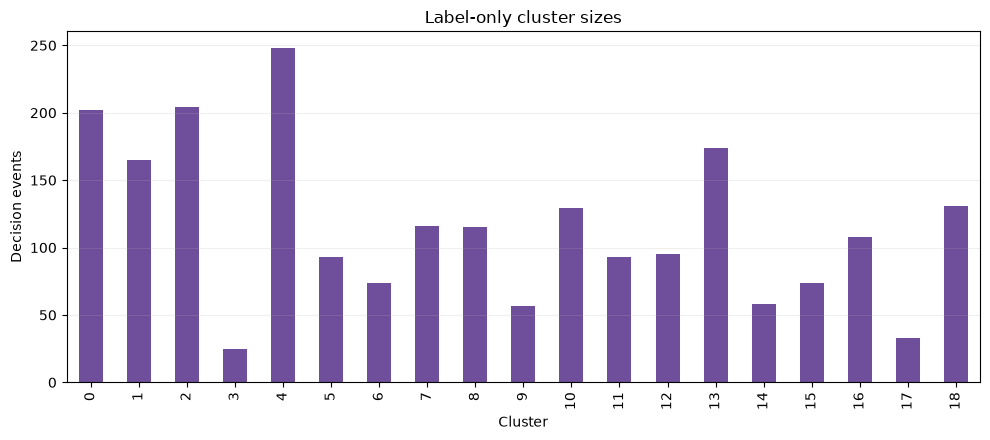

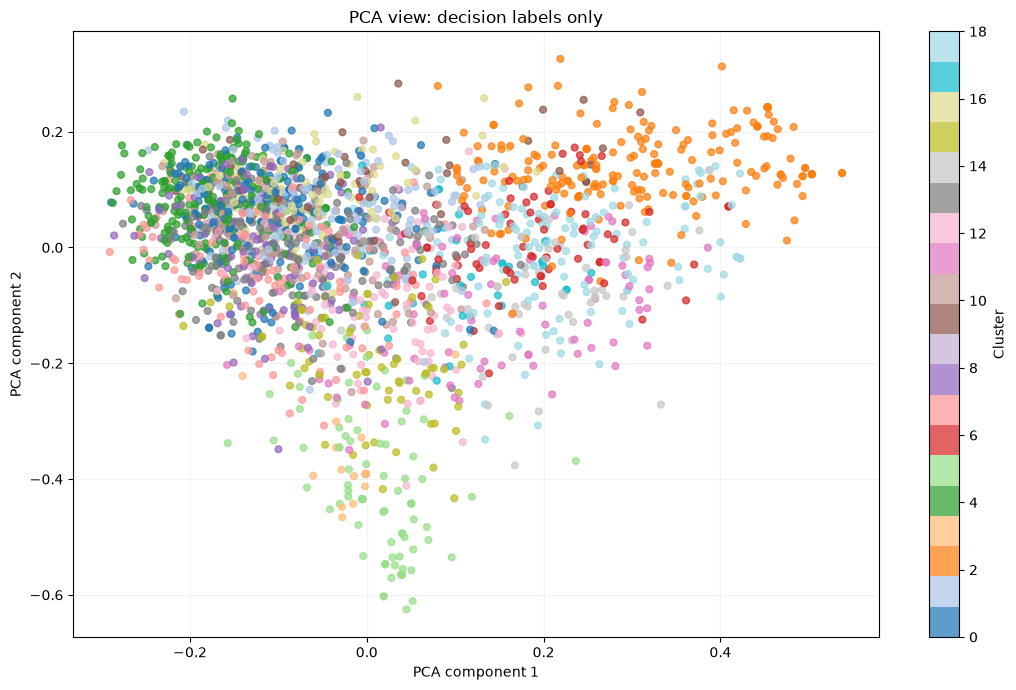

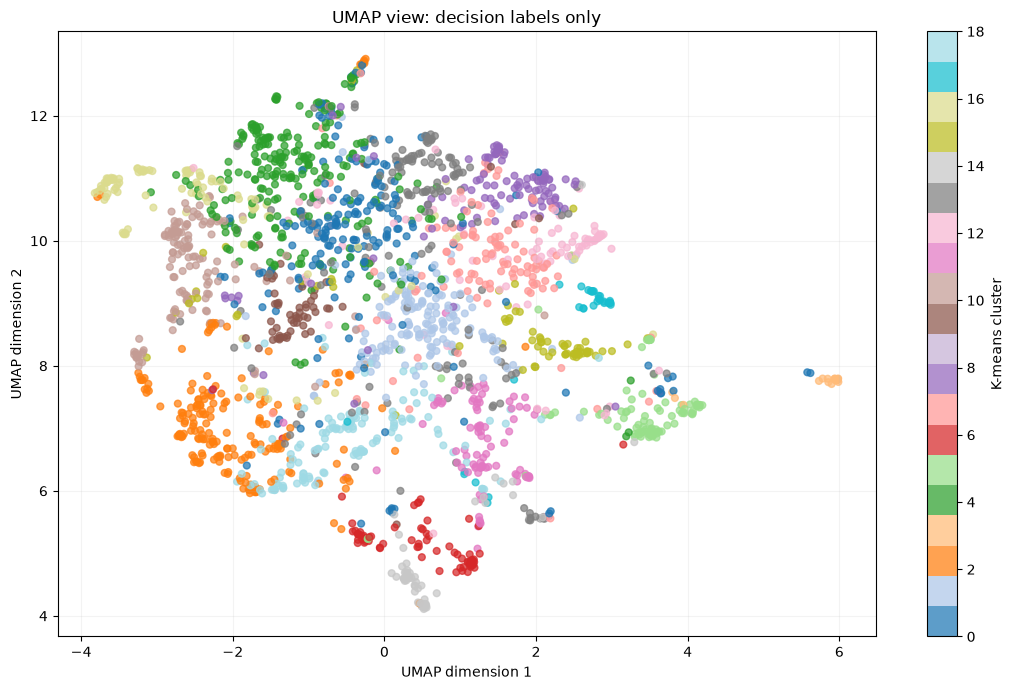

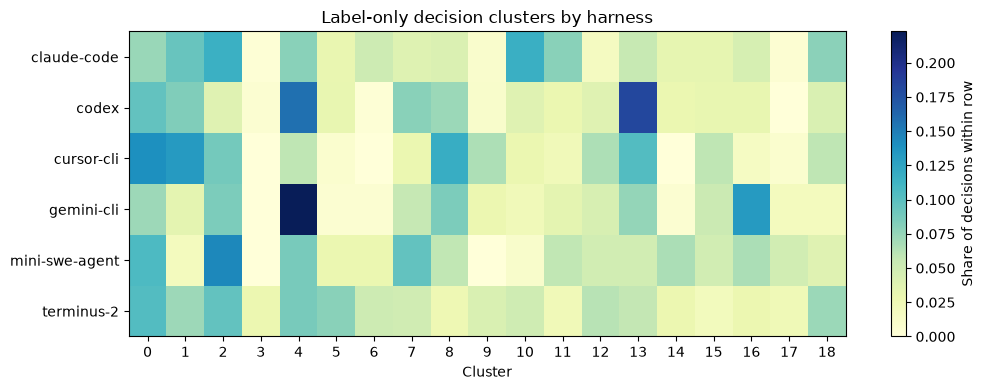

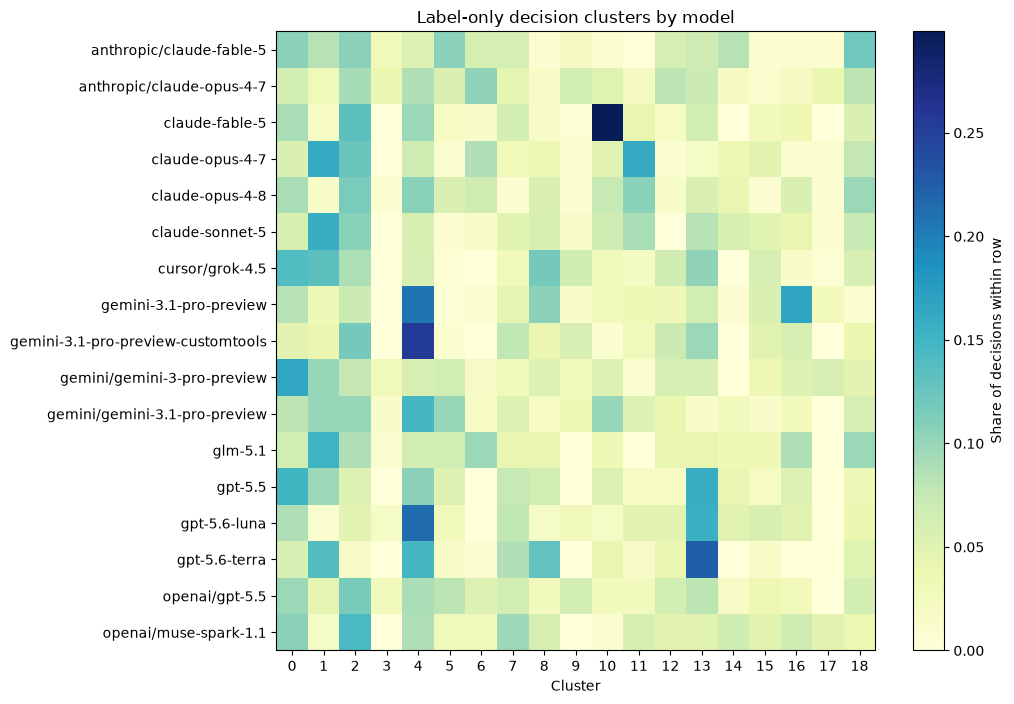

In [ ]:
if label_cluster_model is not None:
    X_label = normalize(label_only_embeddings)

    label_cluster_sizes = label_decisions_df['label_only_cluster'].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    label_cluster_sizes.plot.bar(ax=ax, color='#6f4e9c')
    ax.set_title('Label-only cluster sizes')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Decision events')
    ax.grid(axis='y', alpha=.2)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'label_only_cluster_sizes.png', dpi=180, bbox_inches='tight')
    plt.show()

    X_label_pca = PCA(n_components=2, random_state=SEED).fit_transform(X_label)
    fig, ax = plt.subplots(figsize=(11, 7))
    scatter = ax.scatter(
        X_label_pca[:, 0], X_label_pca[:, 1],
        c=label_decisions_df['label_only_cluster'], cmap='tab20', s=24, alpha=.72,
    )
    ax.set_title('PCA view: decision labels only')
    ax.set_xlabel('PCA component 1')
    ax.set_ylabel('PCA component 2')
    ax.grid(alpha=.15)
    plt.colorbar(scatter, ax=ax, label='Cluster')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'label_only_cluster_map_pca.png', dpi=180, bbox_inches='tight')
    plt.show()

    umap_neighbors = min(30, len(X_label) - 1)
    umap_reducer = umap.UMAP(
        n_components=2, n_neighbors=umap_neighbors, min_dist=0.10,
        metric='cosine', random_state=SEED, n_jobs=1,
    )
    X_label_umap = umap_reducer.fit_transform(X_label)
    fig, ax = plt.subplots(figsize=(11, 7))
    scatter = ax.scatter(
        X_label_umap[:, 0], X_label_umap[:, 1],
        c=label_decisions_df['label_only_cluster'], cmap='tab20', s=24, alpha=.72,
    )
    ax.set_title('UMAP view: decision labels only')
    ax.set_xlabel('UMAP dimension 1')
    ax.set_ylabel('UMAP dimension 2')
    ax.grid(alpha=.15)
    plt.colorbar(scatter, ax=ax, label='K-means cluster')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'label_only_cluster_map_umap.png', dpi=180, bbox_inches='tight')
    plt.show()

    label_harness_distribution = pd.crosstab(
        label_decisions_df['harness'], label_decisions_df['label_only_cluster'], normalize='index',
    ).round(3)
    label_model_distribution = pd.crosstab(
        label_decisions_df['source_model'], label_decisions_df['label_only_cluster'], normalize='index',
    ).round(3)
    label_harness_distribution.to_csv(OUTPUT_DIR / 'label_only_cluster_distribution_by_harness.csv')
    label_model_distribution.to_csv(OUTPUT_DIR / 'label_only_cluster_distribution_by_model.csv')

    plot_distribution_heatmap(
        label_harness_distribution,
        'Label-only decision clusters by harness',
        'label_only_cluster_by_harness_heatmap.png',
    )
    plot_distribution_heatmap(
        label_model_distribution,
        'Label-only decision clusters by model',
        'label_only_cluster_by_model_heatmap.png',
    )

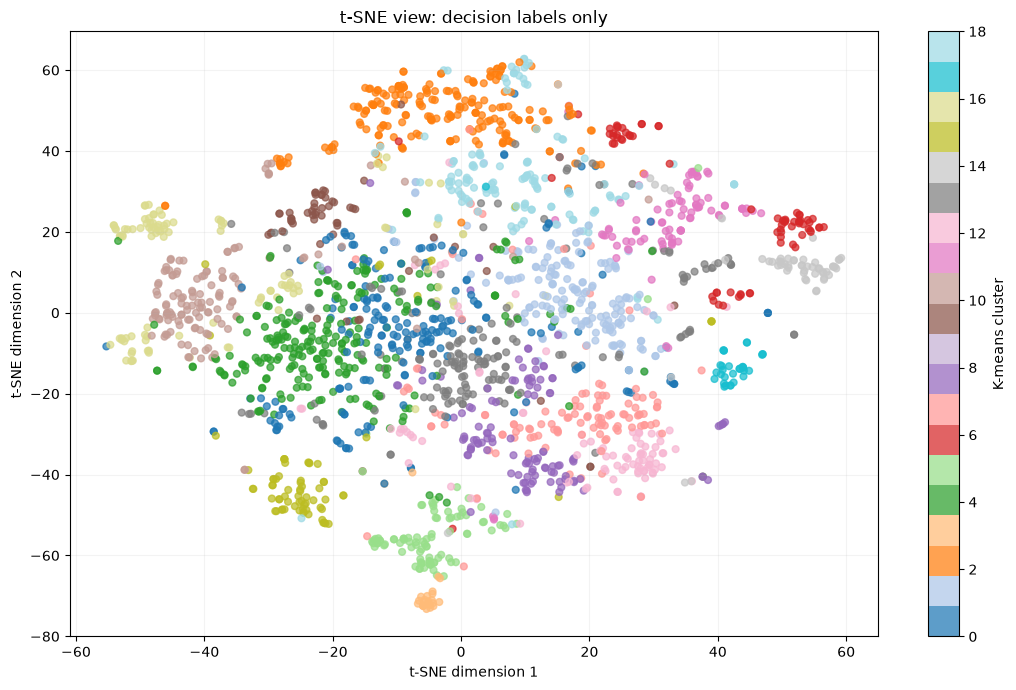

In [ ]:
# t-SNE is an additional visual diagnostic; K-means cluster assignments are unchanged.
if label_cluster_model is None:
    print('No label-only clustering result is available for t-SNE visualization.')
else:
    X_label = normalize(label_only_embeddings)
    label_reduced_dimensions = min(50, X_label.shape[1], len(X_label) - 1)
    X_label_for_tsne = PCA(
        n_components=label_reduced_dimensions, random_state=SEED,
    ).fit_transform(X_label)
    label_tsne_perplexity = min(30, max(5, (len(X_label) - 1) // 3))
    X_label_tsne = TSNE(
        n_components=2,
        perplexity=label_tsne_perplexity,
        init='pca',
        learning_rate='auto',
        max_iter=1_000,
        random_state=SEED,
    ).fit_transform(X_label_for_tsne)

    fig, ax = plt.subplots(figsize=(11, 7))
    scatter = ax.scatter(
        X_label_tsne[:, 0], X_label_tsne[:, 1],
        c=label_decisions_df['label_only_cluster'], cmap='tab20', s=24, alpha=.72,
    )
    ax.set_title('t-SNE view: decision labels only')
    ax.set_xlabel('t-SNE dimension 1')
    ax.set_ylabel('t-SNE dimension 2')
    ax.grid(alpha=.15)
    plt.colorbar(scatter, ax=ax, label='K-means cluster')
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / 'label_only_cluster_map_tsne.png', dpi=180, bbox_inches='tight')
    plt.show()

In [ ]:
if label_cluster_model is not None:
    label_review_parts = []
    for cluster_id, group in label_decisions_df.groupby('label_only_cluster'):
        central = group.nsmallest(3, 'distance_to_label_centroid')
        outliers = group.nlargest(2, 'distance_to_label_centroid')
        label_review_parts.append(central.assign(review_role='central example'))
        label_review_parts.append(outliers.assign(review_role='cluster outlier'))
    label_review_df = pd.concat(label_review_parts, ignore_index=True).sort_values(
        ['label_only_cluster', 'review_role', 'distance_to_label_centroid']
    )
    label_review_columns = [
        'label_only_cluster', 'review_role', 'trajectory_id', 'task_id', 'harness',
        'source_model', 'source_steps', 'decision_type_label', 'decision_summary',
        'visibility', 'distance_to_label_centroid',
    ]
    label_review_df[label_review_columns].to_csv(
        OUTPUT_DIR / 'label_only_cluster_review_sample.csv', index=False,
    )
    print('Saved label_only_cluster_review_sample.csv.')

Saved label_only_cluster_review_sample.csv.


## Evaluation criteria

The baseline label-plus-summary experiment and the label-only experiment are compared using silhouette score, cluster stability, task concentration, and semantic coherence. Stronger clustering is indicated by reusable decision functions rather than task-specific topics.

Each candidate cluster is evaluated through its central examples and outliers. The evaluation considers internal coherence, possible merges or splits, task vocabulary, harness concentration, and evidence of a recurring decision function.

Comparison with the preliminary D1–D8 taxonomy follows the independent inspection of emergent clusters. Any similarity to the preliminary taxonomy is treated as an analytical result rather than information supplied to the extractor.

Model- and harness-level cluster distributions remain provisional until extraction quality and cluster meanings have been validated.

## Main output files

- `sample_manifest_350.csv`: selected trajectories and achieved coverage
- `selected_trajectories_350.jsonl`: full selected input records
- `raw_responses/*.json`: one complete Ollama response per trajectory
- `completed_trajectory_index.csv`: durable list used to skip already-labelled trajectories
- `trajectory_extraction_summary.csv`: extraction-level status and token/runtime data
- `decision_events.csv`: flattened free-text decision events
- `cluster_assignments.csv`: every event with its provisional cluster
- `cluster_summary.csv`: quantitative cluster summary
- `cluster_representatives.csv`: events closest to each centroid
- `cluster_review_sample.csv`: central examples and outliers for human review
- `cluster_distribution_by_harness.csv` and `cluster_distribution_by_model.csv`: baseline provisional RQ1/RQ2 exploration
- `label_only_decision_embeddings.npy`: embeddings created only from `decision_type_label`
- `label_only_cluster_count_scores.csv`: label-only silhouette scores for every tested value of k
- `label_only_cluster_assignments.csv`: label-only provisional cluster for every event
- `label_only_cluster_summary.csv` and `label_only_cluster_representatives.csv`: label-only cluster inspection tables
- `label_only_cluster_review_sample.csv`: central examples and outliers for manual review
- `figures/cluster_map_pca.png`, `cluster_map_tsne.png`, and `cluster_map_umap.png`: baseline label-plus-summary embedding views
- `figures/label_only_cluster_map_pca.png`, `label_only_cluster_map_umap.png`, and `label_only_cluster_map_tsne.png`: label-only embedding views

## Fixed semantic comparison: k = 8, 9, and 10

This section uses the existing **label-plus-summary semantic embeddings** created by `qwen3-embedding:0.6b`. K-means is fitted in the complete normalized embedding space for k = 8, 9, and 10. PCA, t-SNE, and UMAP are visual diagnostics only; none of the two-dimensional projections determines cluster membership.

The cells are intentionally separate from the earlier automatic cluster-count selection so the three candidate solutions can be compared directly without replacing previous outputs.

In [ ]:
SEMANTIC_FOCUS_K = (8, 9, 10)
semantic_focus_models = {}
semantic_focus_metrics_df = pd.DataFrame()
semantic_focus_df = pd.DataFrame()

if embeddings is None or len(embeddings) <= max(SEMANTIC_FOCUS_K):
    print('Run the label-plus-summary semantic embedding cell before this section.')
else:
    X_semantic_focus = normalize(embeddings)
    semantic_focus_df = decisions_df.drop(
        columns=['cluster', 'distance_to_centroid'], errors='ignore',
    ).copy()
    metric_rows = []
    for k in SEMANTIC_FOCUS_K:
        model = KMeans(n_clusters=k, random_state=SEED, n_init=50)
        labels = model.fit_predict(X_semantic_focus)
        semantic_focus_models[k] = model
        semantic_focus_df[f'semantic_cluster_k{k}'] = labels
        sizes = np.bincount(labels)
        metric_rows.append({
            'k': k,
            'inertia': float(model.inertia_),
            'silhouette_cosine': float(silhouette_score(X_semantic_focus, labels, metric='cosine')),
            'smallest_cluster': int(sizes.min()),
            'largest_cluster': int(sizes.max()),
        })

    semantic_focus_metrics_df = pd.DataFrame(metric_rows)
    semantic_focus_metrics_df.to_csv(OUTPUT_DIR / 'semantic_k8_k9_k10_metrics.csv', index=False)
    semantic_focus_df.to_csv(OUTPUT_DIR / 'semantic_k8_k9_k10_assignments.csv', index=False)
    display(semantic_focus_metrics_df)

In [ ]:
def plot_semantic_focus(points, method, filename):
    if not semantic_focus_models:
        print('No fixed-k semantic models are available.')
        return
    fig, axes = plt.subplots(1, len(SEMANTIC_FOCUS_K), figsize=(19, 5.5), sharex=True, sharey=True)
    for ax, k in zip(axes, SEMANTIC_FOCUS_K):
        scatter = ax.scatter(
            points[:, 0], points[:, 1],
            c=semantic_focus_models[k].labels_, cmap='tab10',
            vmin=-0.5, vmax=9.5, s=27, alpha=.76, linewidths=0,
        )
        ax.set_title(f'{method}: k = {k}')
        ax.set_xlabel(f'{method} dimension 1')
        ax.set_ylabel(f'{method} dimension 2')
        ax.grid(alpha=.15)
        colorbar = fig.colorbar(scatter, ax=ax, ticks=np.arange(k), fraction=.047, pad=.03)
        colorbar.set_label('K-means cluster')
    fig.suptitle(f'{method} views of semantic label-plus-summary embeddings', fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

In [ ]:
if semantic_focus_models:
    semantic_pca_points = PCA(n_components=2, random_state=SEED).fit_transform(X_semantic_focus)
    plot_semantic_focus(
        semantic_pca_points, 'PCA', 'semantic_label_summary_pca_k8_k9_k10.png',
    )

In [ ]:
if semantic_focus_models:
    semantic_reduced_dimensions = min(50, X_semantic_focus.shape[1], len(X_semantic_focus) - 1)
    semantic_tsne_input = PCA(
        n_components=semantic_reduced_dimensions, random_state=SEED,
    ).fit_transform(X_semantic_focus)
    semantic_tsne_perplexity = min(30, max(5, (len(X_semantic_focus) - 1) // 3))
    semantic_tsne_points = TSNE(
        n_components=2, perplexity=semantic_tsne_perplexity, init='pca',
        learning_rate='auto', max_iter=1_000, random_state=SEED,
    ).fit_transform(semantic_tsne_input)
    plot_semantic_focus(
        semantic_tsne_points, 't-SNE', 'semantic_label_summary_tsne_k8_k9_k10.png',
    )

In [ ]:
if semantic_focus_models:
    import umap.umap_ as umap

    semantic_umap_points = umap.UMAP(
        n_components=2, n_neighbors=min(30, len(X_semantic_focus) - 1),
        min_dist=.10, metric='cosine', random_state=SEED, n_jobs=1,
    ).fit_transform(X_semantic_focus)
    plot_semantic_focus(
        semantic_umap_points, 'UMAP', 'semantic_label_summary_umap_k8_k9_k10.png',
    )

In [ ]:
semantic_focus_summaries = {}
if semantic_focus_models:
    for k, model in semantic_focus_models.items():
        working = semantic_focus_df.copy()
        cluster_column = f'semantic_cluster_k{k}'
        distances = model.transform(X_semantic_focus)
        working['distance_to_centroid'] = distances[
            np.arange(len(working)), working[cluster_column].to_numpy(),
        ]
        summary_rows = []
        representative_parts = []
        for cluster_id, group in working.groupby(cluster_column, sort=True):
            top_labels = group['decision_type_label'].value_counts().head(8)
            summary_rows.append({
                'cluster': int(cluster_id),
                'n_events': len(group),
                'n_trajectories': group['trajectory_id'].nunique(),
                'n_tasks': group['task_id'].nunique(),
                'top_labels': ' | '.join(f'{label} ({count})' for label, count in top_labels.items()),
            })
            representative_parts.append(group.nsmallest(5, 'distance_to_centroid'))

        summary_df = pd.DataFrame(summary_rows)
        representatives_df = pd.concat(representative_parts, ignore_index=True)
        summary_df.to_csv(OUTPUT_DIR / f'semantic_cluster_summary_k{k}.csv', index=False)
        representatives_df.to_csv(OUTPUT_DIR / f'semantic_cluster_representatives_k{k}.csv', index=False)
        semantic_focus_summaries[k] = summary_df
        print(f'k = {k}')
        display(summary_df)